# U04 — Frontloading evaluation of the saved six-arm sweep

**Evaluation only. No rewrite generation, no changes to generation contracts.**
Shut down the U04 generation kernel to free Llama GPU memory, then run this
notebook in a fresh kernel from `experiments/`. Inputs are the existing U04 run JSONs,
U03 direct-prompt outputs, original RAID AI texts, and matched HUMAN references.
Human prose is loaded **only into this evaluation notebook**.

The main benchmark is **context utility** `U(k) = L8 − Lk`, using the frozen
**Qwen/Qwen3-0.6B-Base** scorer from U01b/U01c/U01d. This is different from U03's
whole-text **word**-surprisal highlighting checkpoint/convention.

- **U128:** exact U01b target rule: first 256 scorer tokens, eight equally spaced
  integer target positions from 128 through 255 (zero-based), contexts of 8 and 128 tokens.
- **U256:** explicitly extends that rule to first 512 tokens, eight target positions
  256 through 511, contexts of 8 and 256 tokens. Both losses use the same targets.
- Audit eligibility **before examining scores**. Use U256 as primary if at least
  8 of the 10 cases support all nine conditions; otherwise use U128. Show both
  results wherever supported and list exclusions. Never substitute U128 for individual
  U256-ineligible rows in one mean. No threshold is chosen based on observed effects.
- **U01d survival:** first 256 scorer tokens, shared per-case endpoint across all
  nine conditions, then discard `ceil(.20 × full OG token count)` loss entries.
  Plot pooled token survival `P(S > τ)` on a log y-axis, just as U01d.
- **U01c innovation persistence:** the same warmup cut and relative bins
  1–32, 33–64, 65–96, 97–128, 129–192, at thresholds 3, 4, 6, 8 nats.
  Plot the original 256-token scope and a clearly labeled extension through the
  shared full-text prefix (maximum 1,024 tokens), with extra later bins.
  “Innovation” here means a high-surprisal token event, not verified new facts.
- Show paired U changes vs DP, and late-minus-early changes within the same texts
  to make the frontloading question explicit. A rise in mean surprisal alone is
  not the success criterion. U is a context-dependence measure; persistence supplies
  the direct positional diagnostic.

Every text/metric is checkpointed atomically. Restart this notebook and rerun to
skip finished scoring. It never loads Llama or runs the old generation notebook.
Figures are saved as PDF and PNG in `ROOT/figures/` and the evaluation folder.

In [1]:
from pathlib import Path
import os,json,hashlib,tempfile,math,gc,time
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from transformers import AutoTokenizer, AutoModelForCausalLM
from IPython.display import display

ROOT = next((p for p in [Path.cwd().resolve(),*Path.cwd().resolve().parents,
    Path.home()/"Downloads/TemporalContextResearch/reproduction"]
    if (p/"results/causal/U04_context_range_sweep_v1/contract.json").exists()),None)
assert ROOT is not None, "Cannot find the saved U04 contract; set ROOT to your reproduction directory."
GEN_DIR = ROOT/"results/causal/U04_context_range_sweep_v1"
U03_DIR = ROOT/"results/causal/U03_INFO_POOL_ALL20_GENERAL_v2"
EVAL_DIR = GEN_DIR/"frontloading_evaluation_v1"
CACHE = EVAL_DIR/"cache"
FIG_DIR = ROOT/"figures"
for p in (EVAL_DIR,CACHE,FIG_DIR,EVAL_DIR/"figures"):p.mkdir(parents=True,exist_ok=True)

SCORER_ID = "Qwen/Qwen3-0.6B-Base"
MIN_U256_MATCHED_CASES = 8
MAX_POSITION_TOKENS = 1024
WARMUP_FRACTION = .20
TARGET_COUNT = 8
UTILITY_BATCH_SIZE = 4
LOGIT_CHUNK = 128
N_BOOT = 10000
BOOT_SEED = 20260920
POSITION_TAILS = [3,4,6,8]
ORIGINAL_BINS = [(1,32),(33,64),(65,96),(97,128),(129,192)]
EXTENDED_BINS = ORIGINAL_BINS+[(193,256),(257,384),(385,512),(513,768)]

# Match U01's usual CUDA fp16 / CPU fp32 scoring; load only this small scorer.
EVAL_DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
EVAL_DTYPE = torch.float16 if EVAL_DEVICE.type=="cuda" else torch.float32

def sha_text(x):return hashlib.sha256(str(x).encode()).hexdigest()
def normalize(x):
    if isinstance(x,dict):return {str(k):normalize(v) for k,v in x.items()}
    if isinstance(x,(list,tuple)):return [normalize(v) for v in x]
    if isinstance(x,np.generic):return normalize(x.item())
    if isinstance(x,float) and not math.isfinite(x):return None
    return x

def fingerprint(x):return sha_text(json.dumps(normalize(x),sort_keys=True,ensure_ascii=False))
def atomic_json(path,x):
    path=Path(path)
    fd,tmp=tempfile.mkstemp(dir=path.parent,prefix=path.name+'.',suffix='.tmp')
    try:
        with os.fdopen(fd,'w') as f:
            json.dump(normalize(x),f,ensure_ascii=False,indent=2,allow_nan=False)
            f.flush();os.fsync(f.fileno())
        os.replace(tmp,path)
        fd=os.open(str(path.parent),os.O_RDONLY)
        try:os.fsync(fd)
        finally:os.close(fd)
    finally:
        if os.path.exists(tmp):os.unlink(tmp)

def savefig(fig,name):
    for folder in (FIG_DIR,EVAL_DIR/'figures'):
        fig.savefig(folder/(name+'.pdf'),bbox_inches='tight')
        fig.savefig(folder/(name+'.png'),dpi=240,bbox_inches='tight')
    plt.show();plt.close(fig)

contract=json.loads((GEN_DIR/'contract.json').read_text())
CASES=list(contract['cases'])
ARMS=list(contract['arms'])
ORDER=['HUMAN','OG','DIRECT_PROMPT']+ARMS
assert len(CASES)==10 and len(ARMS)==6
COLORS=dict(zip(ORDER,['#23966F','#858C96','#D77927','#4575B4','#8064A2','#268DAB','#D14B5A','#956029','#373A8C']))
LABELS={'HUMAN':'Human','OG':'Original RAID AI','DIRECT_PROMPT':'U03 DP',**{x:x for x in ARMS}}
print('Scoring device:',EVAL_DEVICE,'| output:',EVAL_DIR)

/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Scoring device: cuda | output: ../results/causal/U04_context_range_sweep_v1/frontloading_evaluation_v1


## 1. Recover and verify the exact 90 saved texts — evaluation only

In [2]:
corpus=pd.read_parquet(ROOT/'results/causal/C02d2_fz118_ghostbuster_raid/paired_corpus.parquet')
cohort=pd.read_csv(ROOT/'results/causal/U01_temporal_method_selection/cohort20.csv',keep_default_na=False)
cohort=cohort.set_index('case_id').loc[CASES].reset_index()
u03_panel=pd.read_parquet(U03_DIR/'comparison_reused_u02/generations.parquet')
def source_key(x):return str(x).split('raid:',1)[-1]
humans=corpus.loc[corpus.label.eq(0)].copy()
humans['_source_key']=humans.source_id.map(source_key)
frozen_inputs={r['case_id']:r for r in contract['case_inputs']}
records=[]
for r in cohort.itertuples(index=False):
    cid=str(r.case_id); frozen=frozen_inputs[cid]
    assert str(r.source_id)==frozen['source_id'] and sha_text(r.prompt)==frozen['task_sha']
    ai=corpus.loc[corpus.label.eq(1)&corpus.source_id.astype(str).eq(str(r.source_id))]
    assert len(ai)==1, (cid,'AI source ambiguity')
    og=str(ai.iloc[0].text)
    assert sha_text(og)==frozen['previous_ai_sha']
    human=humans.loc[humans._source_key.eq(source_key(r.source_id))&humans.domain.astype(str).eq(str(r.domain))]
    assert len(human)==1,(cid,'human reference ambiguity')
    dp=u03_panel.loc[u03_panel.case_id.astype(str).eq(cid)&u03_panel.arm.eq('DIRECT_PROMPT')&u03_panel.replicate.eq(0)]
    assert len(dp)==1,(cid,'DP ambiguity')
    dptext=str(dp.iloc[0].generated_text)
    provenance=next(x for x in contract['benchmark_provenance'] if x['case_id']==cid)
    assert sha_text(dptext)==provenance['dp_text_sha']
    texts={'HUMAN':str(human.iloc[0].text),'OG':og,'DIRECT_PROMPT':dptext}
    stops={'HUMAN':'reference','OG':'reference','DIRECT_PROMPT':provenance['dp_stop_reason']}
    for arm in ARMS:
        p=GEN_DIR/'runs'/f'{cid}__{arm}.json'
        assert p.exists(),f'Missing saved run: {p}. This notebook cannot generate it.'
        item=json.loads(p.read_text());summary=item['summary'];spec=item['spec']
        assert spec['contract_sha']==fingerprint(contract)
        assert item['record_sha']==fingerprint({k:v for k,v in item.items() if k!='record_sha'})
        assert spec['case_id']==cid and spec['arm']==arm
        assert spec['previous_ai_sha']==sha_text(og) and spec['task_sha']==sha_text(r.prompt)
        assert summary['stop_reason'] in {'eos','truncated'}
        assert summary['text_sha']==sha_text(summary['generated_text'])
        texts[arm]=summary['generated_text'];stops[arm]=summary['stop_reason']
    for group,text in texts.items():
        assert isinstance(text,str) and text.strip()
        records.append(dict(case_id=cid,domain=str(r.domain),group=group,text=text,text_sha=sha_text(text),stop_reason=stops[group]))
panel=pd.DataFrame(records)
assert len(panel)==90 and not panel.duplicated(['case_id','group']).any()
manifest=panel.drop(columns='text').to_dict('records')
atomic_json(EVAL_DIR/'text_manifest.json',manifest)
display(panel.groupby(['group','stop_reason']).size().unstack(fill_value=0))
print('90 texts verified. No text generation will be executed.')

stop_reason,eos,reference,truncated
group,,,
DIRECT_PROMPT,9,0,1
END_075,8,0,2
END_125,10,0,0
FRONT_075,9,0,1
FRONT_125,8,0,2
HUMAN,0,10,0
MID_075,8,0,2
MID_125,9,0,1
OG,0,10,0


90 texts verified. No text generation will be executed.


## 2. Token-length audit and primary U choice — before any effect estimates

In [3]:
import transformers
# Preserve the scorer revision chosen on the first evaluation run.
scorer_pin=EVAL_DIR/'scorer_pin.json'
revision=json.loads(scorer_pin.read_text())['revision'] if scorer_pin.exists() else None
etok=AutoTokenizer.from_pretrained(SCORER_ID,revision=revision,use_fast=True)
escorer=AutoModelForCausalLM.from_pretrained(SCORER_ID,revision=revision,
    torch_dtype=EVAL_DTYPE,low_cpu_mem_usage=True).to(EVAL_DEVICE).eval()
resolved=getattr(escorer.config,'_commit_hash',None)
assert resolved, 'Cannot identify frozen scorer revision.'
if revision:assert resolved==revision
else:atomic_json(scorer_pin,dict(model=SCORER_ID,revision=resolved))
TOKEN_IDS={(r.case_id,r.group):etok(r.text,add_special_tokens=False)['input_ids']
           for r in panel.itertuples(index=False)}
lengths=pd.DataFrame([dict(case_id=cid,group=g,n_tokens=len(ids)) for (cid,g),ids in TOKEN_IDS.items()])
length_wide=lengths.pivot(index='case_id',columns='group',values='n_tokens').reindex(index=CASES,columns=ORDER)
eligible={k:[cid for cid in CASES if (length_wide.loc[cid]>=2*k).all()] for k in (128,256)}
PRIMARY_K=256 if len(eligible[256])>=MIN_U256_MATCHED_CASES else 128
eligibility_rows=[]
for k in (128,256):
    for cid in CASES:
        failed=length_wide.columns[length_wide.loc[cid]<2*k].tolist()
        eligibility_rows.append(dict(case_id=cid,k=k,required_tokens=2*k,eligible=not failed,
                                     limiting_groups=', '.join(failed),shortest_text_tokens=int(length_wide.loc[cid].min())))
eligibility=pd.DataFrame(eligibility_rows)
eligibility.to_csv(EVAL_DIR/'utility_eligibility.csv',index=False)
length_wide.to_csv(EVAL_DIR/'scorer_token_lengths.csv')
display(length_wide)
display(eligibility)
print(f'U256: {len(eligible[256])}/10 globally matched cases; U128: {len(eligible[128])}/10.')
print(f'Primary: U{PRIMARY_K}; criterion: at least {MIN_U256_MATCHED_CASES}/10 cases for U256.')
if not eligible[PRIMARY_K]:
    print('No primary-U common support. U plots will be omitted; survival/persistence still run.')

EVAL_SPEC=dict(version='U04_frontloading_eval_v1',model=SCORER_ID,revision=resolved,
    dtype=str(EVAL_DTYPE),device_type=EVAL_DEVICE.type,torch=torch.__version__,transformers=transformers.__version__,
    utility='L8-Lk; targets=unique(linspace(k,2*k-1,8,dtype=int)); contexts reset positions like U01b',
    primary_k=PRIMARY_K,min_u256_cases=MIN_U256_MATCHED_CASES,
    max_position_tokens=MAX_POSITION_TOKENS,post_cut_fraction=WARMUP_FRACTION,
    original_survival_cap=256,original_bins=ORIGINAL_BINS,extended_bins=EXTENDED_BINS,
    utility_batch=UTILITY_BATCH_SIZE,logit_chunk=LOGIT_CHUNK,bootstrap_seed=BOOT_SEED,
    manifest_sha=fingerprint(manifest),generation_contract_sha=fingerprint(contract))
frozen=EVAL_DIR/'evaluation_contract.json'
if frozen.exists():assert json.loads(frozen.read_text())==normalize(EVAL_SPEC),'Evaluation settings changed: use a new evaluation folder.'
else:atomic_json(frozen,EVAL_SPEC)
EVAL_SHA=fingerprint(EVAL_SPEC)

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!
Loading weights: 100%|██████████████████████████████████████████████████████████████████████████████████| 310/310 [00:00<00:00, 2813.92it/s]


group,HUMAN,OG,DIRECT_PROMPT,FRONT_075,MID_075,END_075,FRONT_125,MID_125,END_125
case_id,,,,,,,,,
gate_0090,216,229,567,398,512,565,368,455,440
gate_0070,274,267,333,533,478,333,553,527,502
gate_0017,497,394,406,366,424,447,558,578,488
gate_0085,348,299,624,650,646,646,646,647,607
gate_0038,173,142,399,396,360,290,408,265,321
gate_0039,198,207,340,365,494,467,474,400,452
gate_0069,144,129,366,420,343,464,308,359,336
gate_0035,286,265,517,280,429,505,480,516,548
gate_0003,428,427,496,625,475,370,362,554,508


,case_id,k,required_tokens,eligible,limiting_groups,shortest_text_tokens
0,gate_0090,128,256,False,"HUMAN, OG",216
1,gate_0070,128,256,True,,267
2,gate_0017,128,256,True,,366
3,gate_0085,128,256,True,,299
4,gate_0038,128,256,False,"HUMAN, OG",142
5,gate_0039,128,256,False,"HUMAN, OG",198
6,gate_0069,128,256,False,"HUMAN, OG",129
7,gate_0035,128,256,True,,265
8,gate_0003,128,256,True,,362
9,gate_0025,128,256,True,,341


U256: 0/10 globally matched cases; U128: 6/10.
Primary: U128; criterion: at least 8/10 cases for U256.


## 3. Resume scoring: per-token losses and U128/U256

In [4]:
def cached_metric(text_sha,kind,compute):
    spec=dict(evaluation_sha=EVAL_SHA,text_sha=text_sha,kind=kind)
    path=CACHE/(fingerprint(spec)+'.json')
    if path.exists():
        saved=json.loads(path.read_text());assert saved['spec']==spec
        assert saved['value_sha']==fingerprint(saved['value']),f'Corrupt score: {path}'
        return saved['value']
    value=normalize(compute())
    atomic_json(path,dict(spec=spec,value=value,value_sha=fingerprint(value)))
    return value

@torch.inference_mode()
def positional_losses(ids):
    ids=list(ids[:MAX_POSITION_TOKENS])
    result=[]
    # Compute only the chunk of final logits needed for this pass, retaining full prefix context.
    # Loss entry j predicts scorer-token position j+1 (zero-based target position).
    for start in range(0,len(ids)-1,LOGIT_CHUNK):
        end=min(start+LOGIT_CHUNK,len(ids)-1)
        x=torch.tensor([ids[:end]],device=EVAL_DEVICE)
        y=torch.tensor(ids[start+1:end+1],device=EVAL_DEVICE)
        out=escorer(input_ids=x,use_cache=False,logits_to_keep=end-start)
        loss=F.cross_entropy(out.logits[0].float(),y,reduction='none')
        result.extend(loss.cpu().double().tolist())
        del out,x,y,loss
    return result

@torch.inference_mode()
def context_utility(ids,k):
    if len(ids)<2*k:return dict(eligible=False,k=k,required_tokens=2*k,n_tokens=len(ids))
    ids=list(ids[:2*k]);targets=np.unique(np.linspace(k,2*k-1,TARGET_COUNT,dtype=int))
    losses={}
    for context in (8,k):
        vals=[]
        for start in range(0,len(targets),UTILITY_BATCH_SIZE):
            t=targets[start:start+UTILITY_BATCH_SIZE]
            x=torch.tensor([ids[j-context:j] for j in t],device=EVAL_DEVICE)
            y=torch.tensor([ids[j] for j in t],device=EVAL_DEVICE)
            out=escorer(input_ids=x,use_cache=False,logits_to_keep=1)
            ce=F.cross_entropy(out.logits[:,-1].float(),y,reduction='none')
            vals.extend(ce.cpu().double().tolist());del out,x,y,ce
        losses[str(context)]=vals
    delta=np.asarray(losses['8'])-np.asarray(losses[str(k)])
    return dict(eligible=True,k=k,targets=targets.tolist(),loss8=losses['8'],lossk=losses[str(k)],
                delta_per_target=delta.tolist(),U=float(delta.mean()))

LOSSES={};UTILITY={};utility_rows=[]
for i,r in enumerate(panel.itertuples(index=False),1):
    ids=TOKEN_IDS[(r.case_id,r.group)]
    print(f'[{i}/90] {r.case_id} | {r.group}: load/score saved text',flush=True)
    LOSSES[(r.case_id,r.group)]=np.asarray(cached_metric(r.text_sha,'positional_losses',lambda:positional_losses(ids)),float)
    for k in (128,256):
        result=cached_metric(r.text_sha,f'U{k}',lambda:context_utility(ids,k))
        UTILITY[(r.case_id,r.group,k)]=result
        utility_rows.append(dict(case_id=r.case_id,group=r.group,k=k,U=result.get('U',np.nan),
                                 eligible=result['eligible'],n_tokens=len(ids),stop_reason=r.stop_reason))
    pd.DataFrame(utility_rows).to_csv(EVAL_DIR/'context_utility_by_case.csv',index=False)
utility_table=pd.DataFrame(utility_rows)
print('All available scoring is saved. Subsequent plot changes need no rescoring.')

[1/90] gate_0090 | HUMAN: load/score saved text
[2/90] gate_0090 | OG: load/score saved text
[3/90] gate_0090 | DIRECT_PROMPT: load/score saved text
[4/90] gate_0090 | FRONT_075: load/score saved text
[5/90] gate_0090 | MID_075: load/score saved text
[6/90] gate_0090 | END_075: load/score saved text
[7/90] gate_0090 | FRONT_125: load/score saved text
[8/90] gate_0090 | MID_125: load/score saved text
[9/90] gate_0090 | END_125: load/score saved text
[10/90] gate_0070 | HUMAN: load/score saved text
[11/90] gate_0070 | OG: load/score saved text
[12/90] gate_0070 | DIRECT_PROMPT: load/score saved text
[13/90] gate_0070 | FRONT_075: load/score saved text
[14/90] gate_0070 | MID_075: load/score saved text
[15/90] gate_0070 | END_075: load/score saved text
[16/90] gate_0070 | FRONT_125: load/score saved text
[17/90] gate_0070 | MID_125: load/score saved text
[18/90] gate_0070 | END_125: load/score saved text
[19/90] gate_0017 | HUMAN: load/score saved text
[20/90] gate_0017 | OG: load/score s

## 4. Primary context-utility comparison and paired changes versus DP

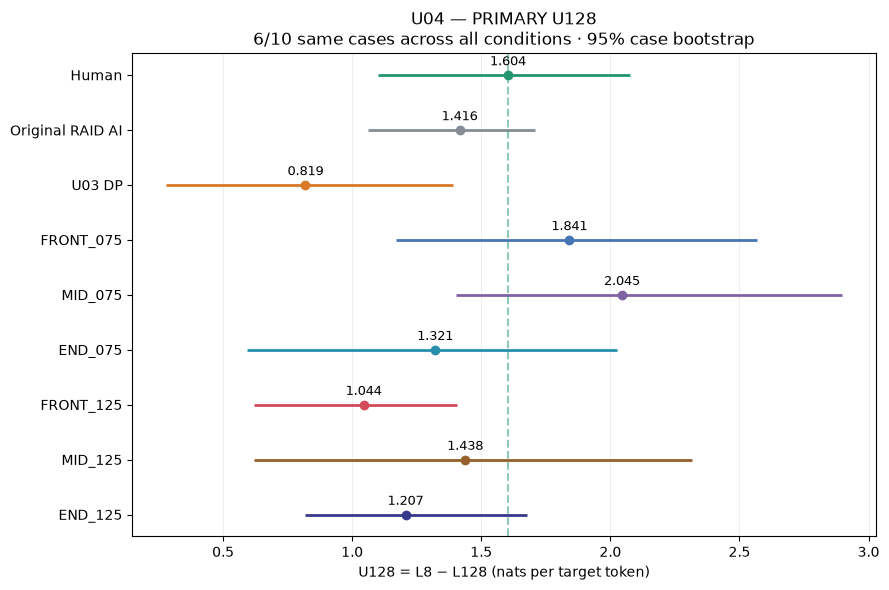

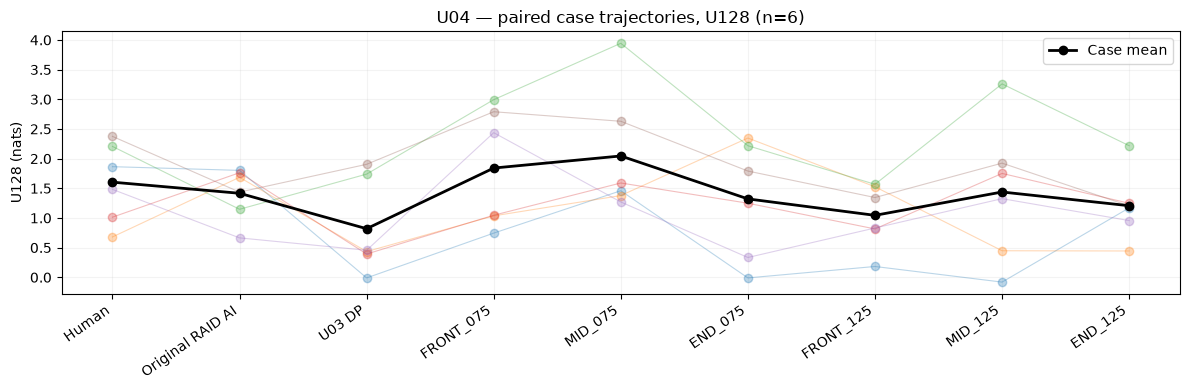

U256: no common eligible cases; no aggregate plotted.


,k,arm,cases,mean_delta_U,ci_low,ci_high,increased,decreased,unchanged
0,128,FRONT_075,6,1.0222,0.7004,1.4480,6,0,0
1,128,MID_075,6,1.2258,0.8700,1.6677,6,0,0
2,128,END_075,6,0.5023,0.0028,1.0977,3,2,1
3,128,FRONT_125,6,0.2253,-0.1798,0.6384,4,2,0
4,128,MID_125,6,0.6187,0.1296,1.1614,5,1,0
5,128,END_125,6,0.3875,-0.1225,0.8418,5,1,0


Interpret against human and OG context utility; do not select an arm solely by higher surprisal.


In [5]:
def bootstrap_mean(matrix):
    matrix=np.asarray(matrix,float)
    rng=np.random.default_rng(BOOT_SEED)
    idx=rng.integers(0,len(matrix),size=(N_BOOT,len(matrix)))
    boot=matrix[idx].mean(axis=1)
    lo,hi=np.quantile(boot,[.025,.975],axis=0)
    return matrix.mean(axis=0),lo,hi,boot

u_means=[];u_pairs=[]
for k in (PRIMARY_K,*(x for x in (128,256) if x!=PRIMARY_K)):
    cs=eligible[k]
    if not cs:
        print(f'U{k}: no common eligible cases; no aggregate plotted.');continue
    wide=utility_table.loc[utility_table.k.eq(k)].pivot(index='case_id',columns='group',values='U').loc[cs,ORDER]
    assert wide.notna().all().all()
    mean,lo,hi,boots=bootstrap_mean(wide.to_numpy())
    fig,ax=plt.subplots(figsize=(9,6))
    for j,g in enumerate(ORDER):
        ax.hlines(j,lo[j],hi[j],color=COLORS[g],lw=2)
        ax.plot(mean[j],j,'o',color=COLORS[g])
        ax.annotate(f'{mean[j]:.3f}',(mean[j],j),xytext=(0,7),textcoords='offset points',ha='center',fontsize=9)
        u_means.append(dict(k=k,group=g,cases=len(cs),mean_U=mean[j],ci_low=lo[j],ci_high=hi[j]))
        if g in ARMS:
            delta=wide[g].to_numpy()-wide['DIRECT_PROMPT'].to_numpy()
            bd=boots[:,j]-boots[:,ORDER.index('DIRECT_PROMPT')]
            dl,dh=np.quantile(bd,[.025,.975])
            u_pairs.append(dict(k=k,arm=g,cases=len(cs),mean_delta_U=delta.mean(),ci_low=dl,ci_high=dh,
                                increased=int((delta>0).sum()),decreased=int((delta<0).sum()),unchanged=int((delta==0).sum())))
    ax.axvline(mean[0],color=COLORS['HUMAN'],ls='--',alpha=.5)
    ax.set_yticks(range(len(ORDER)),[LABELS[g] for g in ORDER]);ax.invert_yaxis()
    ax.set_xlabel(f'U{k} = L8 − L{k} (nats per target token)')
    ax.set_title(f'U04 — {"PRIMARY" if k==PRIMARY_K else "diagnostic"} U{k}\n{len(cs)}/10 same cases across all conditions · 95% case bootstrap')
    ax.grid(axis='x',alpha=.2);fig.tight_layout()
    savefig(fig,f'U04_frontloading_U{k}_comparison')
    # Each line links one case across conditions; useful when means hide divergent effects.
    fig,ax=plt.subplots(figsize=(12,4))
    for cid in cs:ax.plot(range(len(ORDER)),wide.loc[cid].to_numpy(),'o-',alpha=.3,lw=.8)
    ax.plot(range(len(ORDER)),mean,'ko-',lw=2,label='Case mean')
    ax.set_xticks(range(len(ORDER)),[LABELS[g] for g in ORDER],rotation=35,ha='right')
    ax.set_ylabel(f'U{k} (nats)');ax.set_title(f'U04 — paired case trajectories, U{k} (n={len(cs)})')
    ax.grid(alpha=.15);ax.legend();fig.tight_layout();savefig(fig,f'U04_frontloading_U{k}_paired_cases')
pd.DataFrame(u_means).to_csv(EVAL_DIR/'utility_means.csv',index=False)
u_pairs=pd.DataFrame(u_pairs);u_pairs.to_csv(EVAL_DIR/'utility_paired_vs_DP.csv',index=False)
display(u_pairs.round(4))
print('Interpret against human and OG context utility; do not select an arm solely by higher surprisal.')

## 5. U01d token-surprisal survival — same warmup and 256-token scope

,case_id,cap,cut_loss_index,matched_last_target,post_cut_positions,included
0,gate_0090,256,46,215,169,True
1,gate_0070,256,54,255,201,True
2,gate_0017,256,79,255,176,True
3,gate_0085,256,60,255,195,True
4,gate_0038,256,29,141,112,True
5,gate_0039,256,42,197,155,True
6,gate_0069,256,26,128,102,True
7,gate_0035,256,53,255,202,True
8,gate_0003,256,86,255,169,True
9,gate_0025,256,69,255,186,True


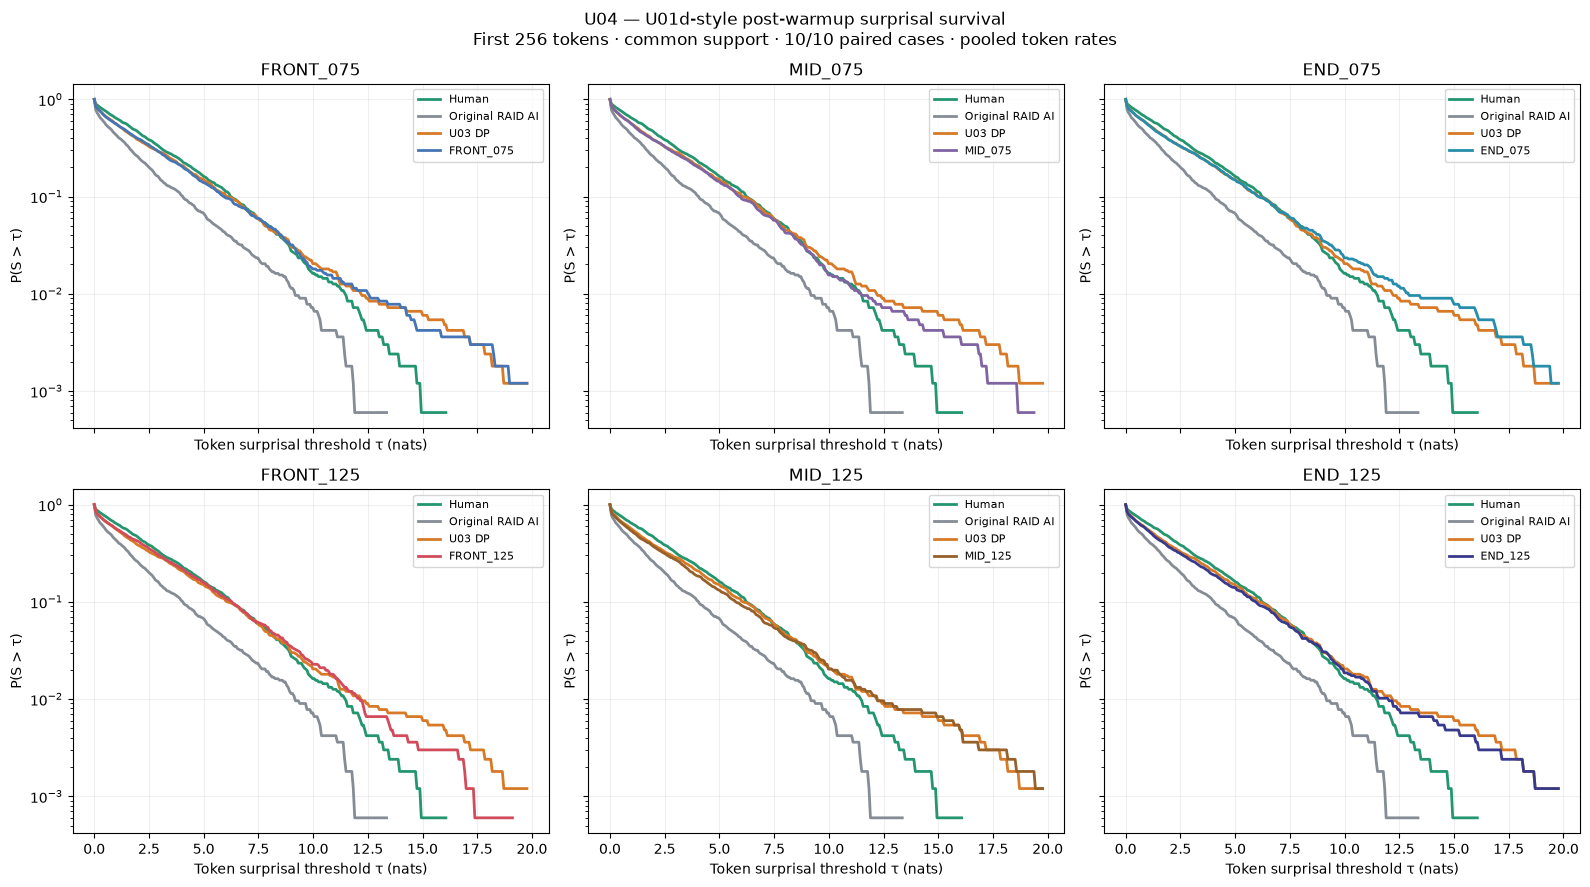

In [6]:
def matched_suffixes(cap):
    suffix={};support=[]
    for cid in CASES:
        cut=int(np.ceil(WARMUP_FRACTION*len(TOKEN_IDS[(cid,'OG')])))
        end=min(cap-1,*[len(LOSSES[(cid,g)]) for g in ORDER])
        accepted=end>cut
        support.append(dict(case_id=cid,cap=cap,cut_loss_index=cut,matched_last_target=end,
                            post_cut_positions=max(0,end-cut),included=accepted))
        if accepted:
            for g in ORDER:suffix[(cid,g)]=LOSSES[(cid,g)][cut:end]
    return suffix,pd.DataFrame(support)

strict_suffix,strict_support=matched_suffixes(256)
full_suffix,full_support=matched_suffixes(MAX_POSITION_TOKENS)
strict_support.to_csv(EVAL_DIR/'survival_256_support.csv',index=False)
full_support.to_csv(EVAL_DIR/'persistence_extended_support.csv',index=False)
display(strict_support)

survival_rows=[]
if strict_suffix:
    cs=strict_support.loc[strict_support.included,'case_id'].tolist()
    pooled={g:np.concatenate([strict_suffix[(cid,g)] for cid in cs]) for g in ORDER}
    xmax=min(20.,max(float(np.quantile(x,.999)) for x in pooled.values()))
    thresholds=np.linspace(0,xmax,300)
    # Six panels keep each intervention legible against the three benchmarks.
    fig,axes=plt.subplots(2,3,figsize=(16,9),sharex=True,sharey=True)
    for ax,arm in zip(axes.flat,ARMS):
        for g in ['HUMAN','OG','DIRECT_PROMPT',arm]:
            surv=np.asarray([np.mean(pooled[g]>t) for t in thresholds])
            ax.plot(thresholds,np.where(surv>0,surv,np.nan),color=COLORS[g],lw=2,label=LABELS[g])
        ax.set_yscale('log');ax.set_title(arm);ax.grid(alpha=.2);ax.legend(fontsize=8)
        ax.set_xlabel('Token surprisal threshold τ (nats)');ax.set_ylabel('P(S > τ)')
    fig.suptitle(f'U04 — U01d-style post-warmup surprisal survival\nFirst 256 tokens · common support · {len(cs)}/10 paired cases · pooled token rates')
    fig.tight_layout();savefig(fig,'U04_U01d_post20_surprisal_survival')
    for g in ORDER:
        for t in thresholds:survival_rows.append(dict(group=g,threshold=t,survival=float(np.mean(pooled[g]>t)),cases=len(cs),tokens=len(pooled[g])))
else:print('No shared post-warmup positions in the first 256 tokens.')
pd.DataFrame(survival_rows).to_csv(EVAL_DIR/'surprisal_survival_256.csv',index=False)

## 6. Innovation persistence and within-case late-minus-early changes

The first figure reproduces U01c's post-warmup bins within its first-256-token
scope. The extended figure uses the same nine-condition shared support through
at most 1,024 tokens. Each bin requires **every condition** to reach its endpoint;
`n` is displayed. Cases can drop out in later bins, so a change in the raw pooled
curve may include composition effects.

The third plot addresses that issue: at every later bin, compare its innovation
rate to the first 32 post-warmup tokens **within each same eligible case**, then
average. Negative values mean less innovation later. This contrasts time positions;
it does not measure whether events are factually correct.

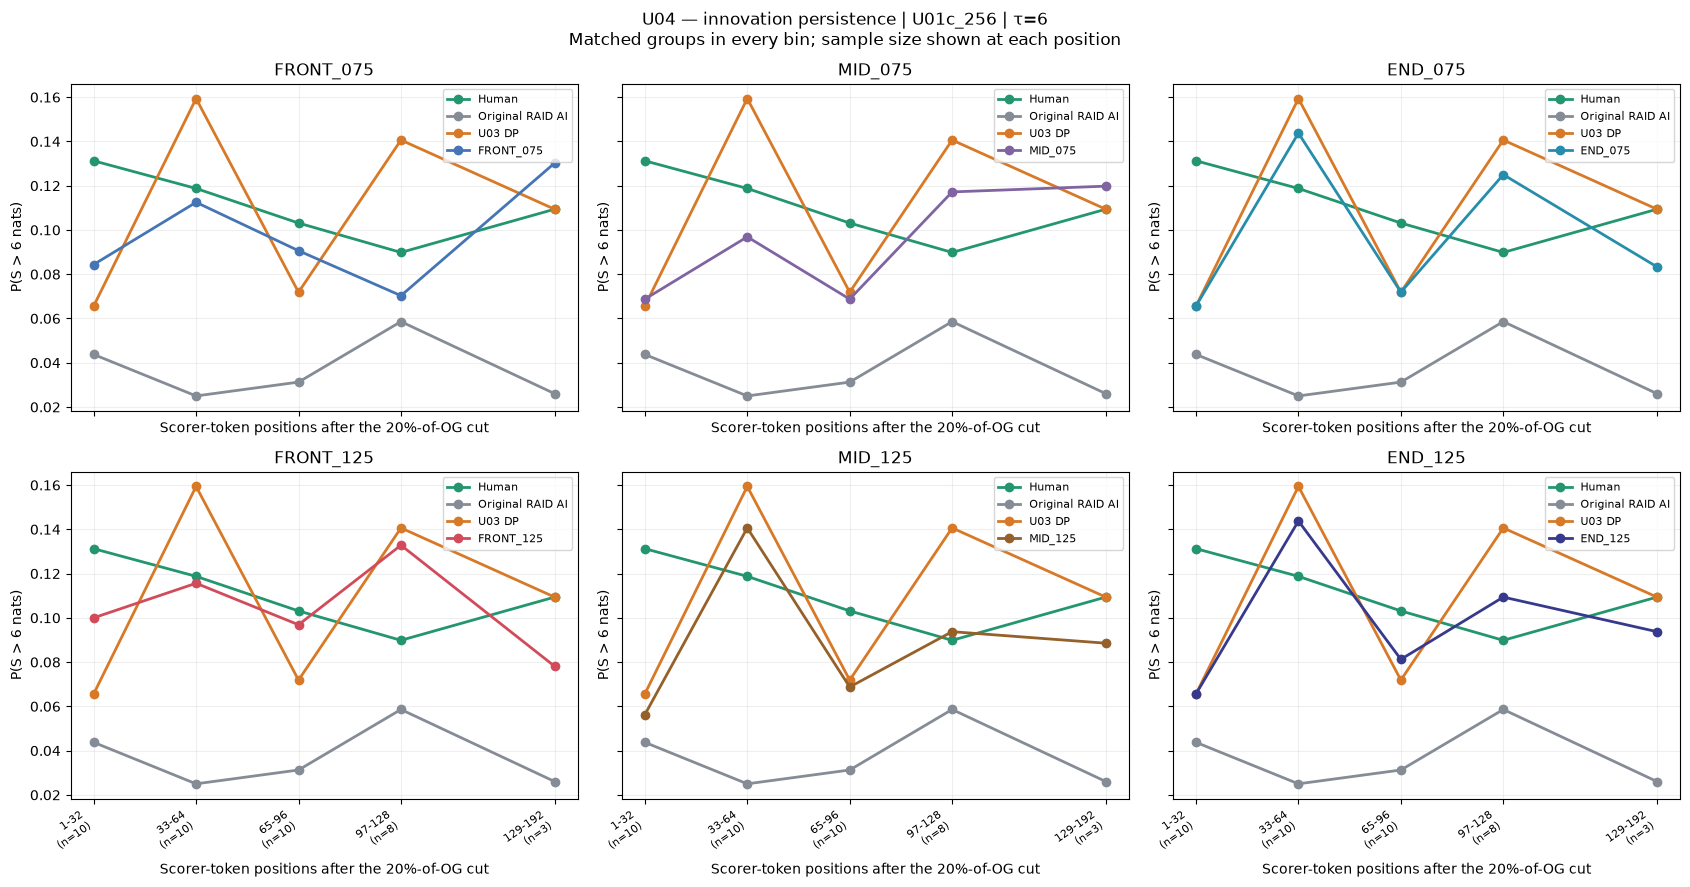

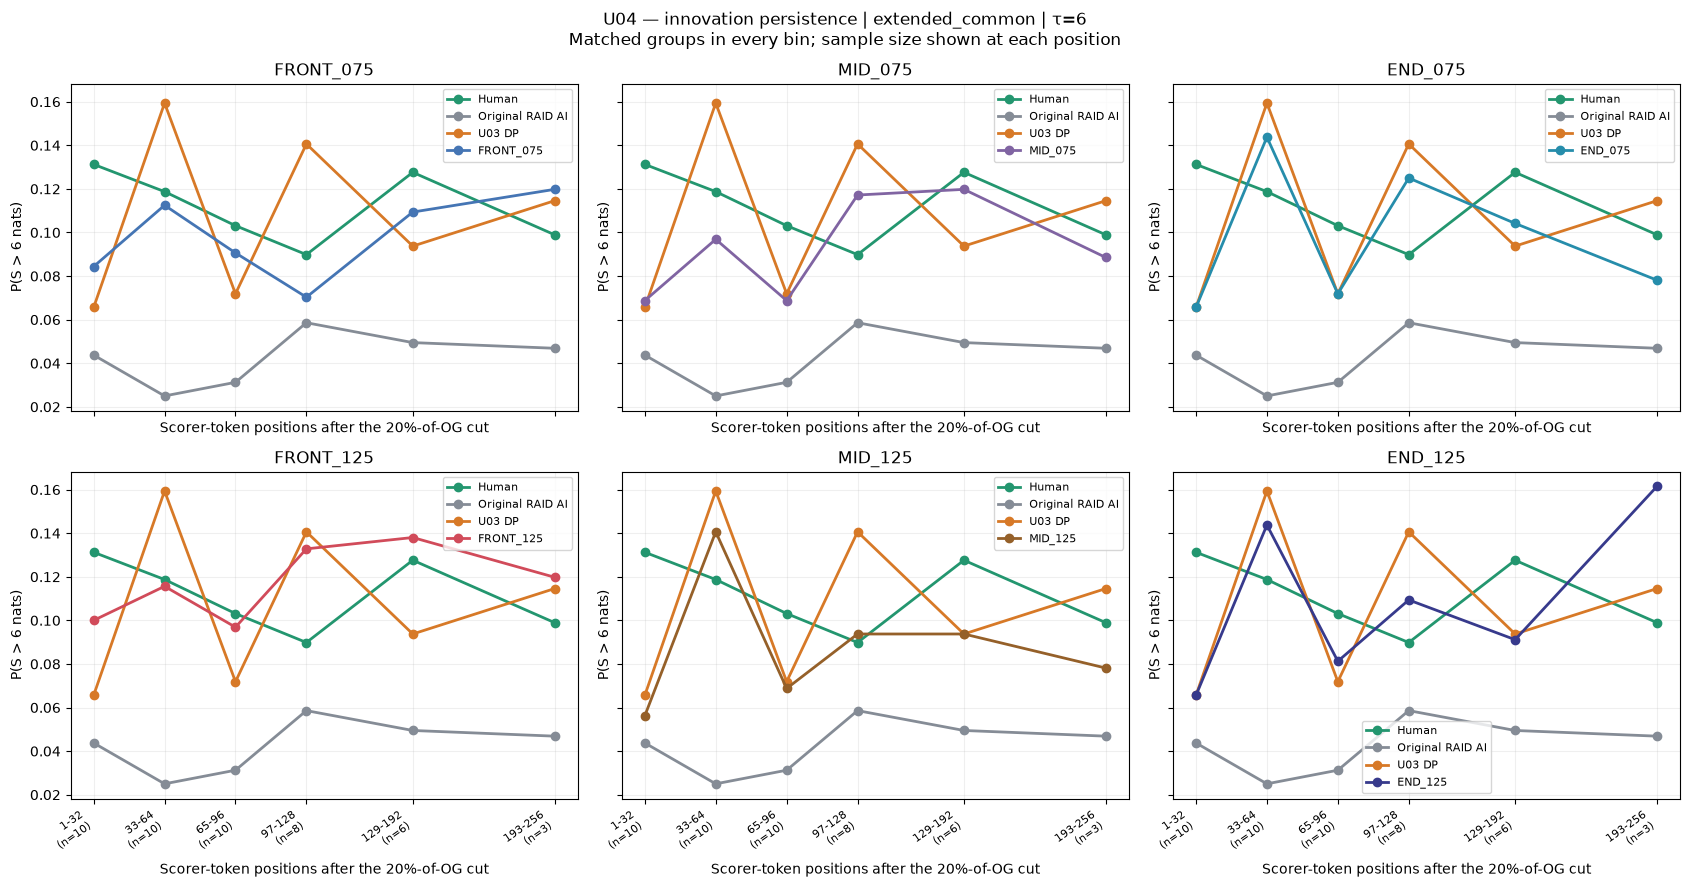

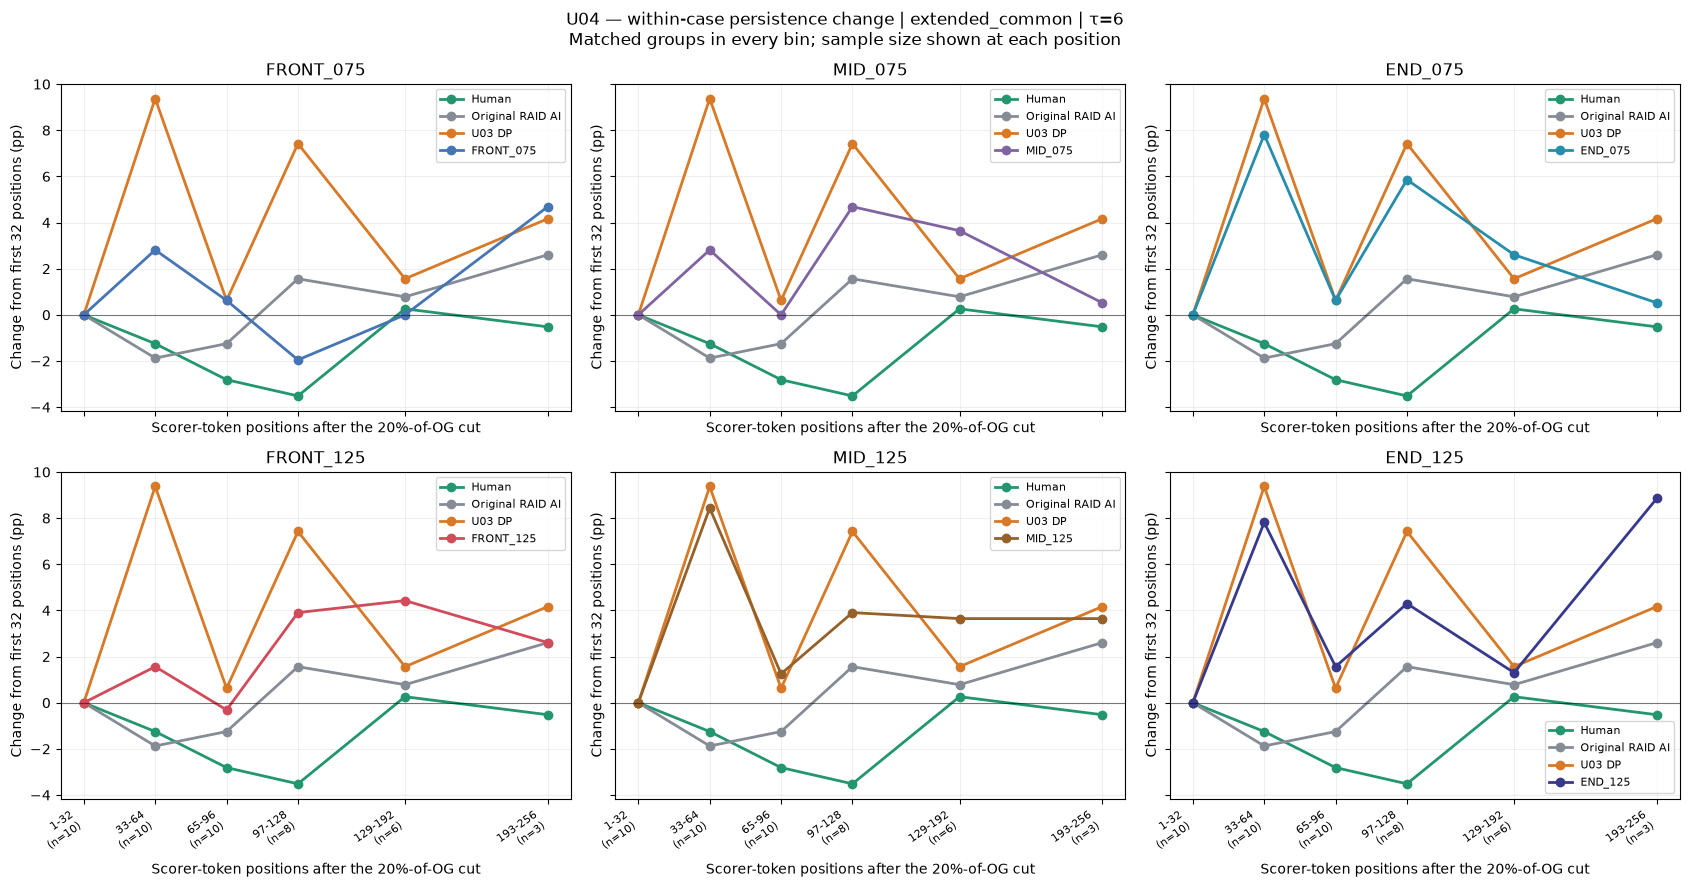

In [7]:
persistence_rows=[];persistence_summary=[]

def persistence(scope,suffix,bins):
    for lo,hi in bins:
        cs=[cid for cid in CASES if (cid,'OG') in suffix and len(suffix[(cid,'OG')])>=hi]
        if not cs:continue
        for tau in POSITION_TAILS:
            current=np.asarray([[np.mean(suffix[(cid,g)][lo-1:hi]>tau) for g in ORDER] for cid in cs])
            first=np.asarray([[np.mean(suffix[(cid,g)][:32]>tau) for g in ORDER] for cid in cs])
            mean,low,high,_=bootstrap_mean(current)
            dmean,dlow,dhigh,_=bootstrap_mean(100*(current-first))
            for j,g in enumerate(ORDER):
                persistence_summary.append(dict(scope=scope,group=g,tau=tau,bin=f'{lo}-{hi}',mid=(lo+hi)/2,
                    cases=len(cs),rate=mean[j],ci_low=low[j],ci_high=high[j],late_minus_first_pp=dmean[j],
                    delta_ci_low=dlow[j],delta_ci_high=dhigh[j]))
                for i,cid in enumerate(cs):
                    persistence_rows.append(dict(scope=scope,case_id=cid,group=g,tau=tau,bin=f'{lo}-{hi}',
                                                 rate=current[i,j],late_minus_first_pp=100*(current[i,j]-first[i,j])))
persistence('U01c_256',strict_suffix,ORIGINAL_BINS)
persistence('extended_common',full_suffix,EXTENDED_BINS)
pos=pd.DataFrame(persistence_summary)
pd.DataFrame(persistence_rows).to_csv(EVAL_DIR/'innovation_persistence_by_case.csv',index=False)
pos.to_csv(EVAL_DIR/'innovation_persistence_summary.csv',index=False)

def plot_persistence(scope,tau=6,difference=False):
    if pos.empty:return
    table=pos.loc[pos.scope.eq(scope)&pos.tau.eq(tau)]
    if table.empty:return
    fig,axes=plt.subplots(2,3,figsize=(17,9),sharex=True,sharey=True)
    ycol='late_minus_first_pp' if difference else 'rate'
    for ax,arm in zip(axes.flat,ARMS):
        for g in ['HUMAN','OG','DIRECT_PROMPT',arm]:
            z=table.loc[table.group.eq(g)].sort_values('mid')
            ax.plot(z.mid,z[ycol],marker='o',lw=2,color=COLORS[g],label=LABELS[g])
        ticks=table.loc[table.group.eq('OG')].sort_values('mid')
        ax.set_xticks(ticks.mid,[f'{b}\n(n={n})' for b,n in zip(ticks['bin'],ticks.cases)],rotation=35,ha='right',fontsize=8)
        if difference:ax.axhline(0,color='black',lw=.8,alpha=.5)
        ax.set_title(arm);ax.legend(fontsize=8);ax.grid(alpha=.2)
        ax.set_xlabel('Scorer-token positions after the 20%-of-OG cut')
        ax.set_ylabel('Change from first 32 positions (pp)' if difference else f'P(S > {tau} nats)')
    kind='within-case persistence change' if difference else 'innovation persistence'
    fig.suptitle(f'U04 — {kind} | {scope} | τ={tau}\nMatched groups in every bin; sample size shown at each position')
    fig.tight_layout()
    savefig(fig,f'U04_{scope}_innovation_tau{tau}'+('_within_case' if difference else ''))

# The historical U01c display uses τ=6; all thresholds are saved above.
plot_persistence('U01c_256',tau=6)
plot_persistence('extended_common',tau=6)
plot_persistence('extended_common',tau=6,difference=True)
# To inspect another saved threshold without any scoring:
# plot_persistence('extended_common', tau=4)

## 7. Compact frontloading summary — paired against DP on identical support

In [8]:
# For each shared suffix >=64 tokens: last 32 vs first 32, same absolute endpoints in every group.
# Positive frontloading gap = higher innovation rate early than late.
front_rows=[]
for cid in CASES:
    if (cid,'OG') not in full_suffix or len(full_suffix[(cid,'OG')])<64:continue
    for g in ORDER:
        x=full_suffix[(cid,g)]
        for tau in POSITION_TAILS:
            early=float(np.mean(x[:32]>tau));late=float(np.mean(x[-32:]>tau))
            front_rows.append(dict(case_id=cid,group=g,tau=tau,positions=len(x),
                                   early=early,late=late,frontloading_gap_pp=100*(early-late)))
front=pd.DataFrame(front_rows)
front.to_csv(EVAL_DIR/'frontloading_early_late_by_case.csv',index=False)
paired_front=[]
if not front.empty:
    for tau in POSITION_TAILS:
        wide=front.loc[front.tau.eq(tau)].pivot(index='case_id',columns='group',values='frontloading_gap_pp').reindex(columns=ORDER)
        assert wide.notna().all().all()
        means,lo,hi,boots=bootstrap_mean(wide.to_numpy())
        for j,arm in enumerate(ORDER):
            if arm not in ARMS:continue
            delta=wide[arm]-wide.DIRECT_PROMPT
            bd=boots[:,j]-boots[:,ORDER.index('DIRECT_PROMPT')]
            dl,dh=np.quantile(bd,[.025,.975])
            paired_front.append(dict(arm=arm,tau=tau,cases=len(wide),gap_mean_pp=means[j],
                DP_gap_mean_pp=means[ORDER.index('DIRECT_PROMPT')],human_gap_mean_pp=means[0],
                delta_gap_vs_DP_pp=delta.mean(),ci_low=dl,ci_high=dh,
                cases_smaller_gap=int((delta<0).sum()),cases_larger_gap=int((delta>0).sum())))
front_comparison=pd.DataFrame(paired_front)
front_comparison.to_csv(EVAL_DIR/'frontloading_paired_vs_DP.csv',index=False)
print(f'Primary context benchmark: U{PRIMARY_K} on {len(eligible[PRIMARY_K])}/10 globally matched cases.')
print('Frontloading: positive early-minus-late gap means declining innovation rate; a negative change vs DP reduces that gap.')
print('Judge the complete profile against HUMAN; do not equate a lower gap with universally better text.')
display(front_comparison.round(3))
print('Saved metrics:',EVAL_DIR)
print('Saved PDF/PNG figures:',FIG_DIR)

Primary context benchmark: U128 on 6/10 globally matched cases.
Frontloading: positive early-minus-late gap means declining innovation rate; a negative change vs DP reduces that gap.
Judge the complete profile against HUMAN; do not equate a lower gap with universally better text.


,arm,tau,cases,gap_mean_pp,DP_gap_mean_pp,human_gap_mean_pp,delta_gap_vs_DP_pp,ci_low,ci_high,cases_smaller_gap,cases_larger_gap
0,FRONT_075,3,10,-5.625,5.000,4.375,-10.625,-24.062,2.188,5,3
1,MID_075,3,10,4.688,5.000,4.375,-0.312,-6.562,6.562,4,4
2,END_075,3,10,0.938,5.000,4.375,-4.062,-10.938,2.812,6,2
3,FRONT_125,3,10,-5.312,5.000,4.375,-10.312,-26.875,3.750,5,4
4,MID_125,3,10,6.250,5.000,4.375,1.250,-7.812,10.625,4,4
5,END_125,3,10,5.000,5.000,4.375,0.000,-7.500,6.875,4,4
6,FRONT_075,4,10,-8.438,1.562,5.312,-10.000,-21.562,0.938,6,4
7,MID_075,4,10,1.250,1.562,5.312,-0.312,-5.000,5.625,6,3
8,END_075,4,10,-1.562,1.562,5.312,-3.125,-10.000,4.062,6,2
9,FRONT_125,4,10,-4.062,1.562,5.312,-5.625,-23.445,8.125,5,5


Saved metrics: ../results/causal/U04_context_range_sweep_v1/frontloading_evaluation_v1
Saved PDF/PNG figures: ../figures


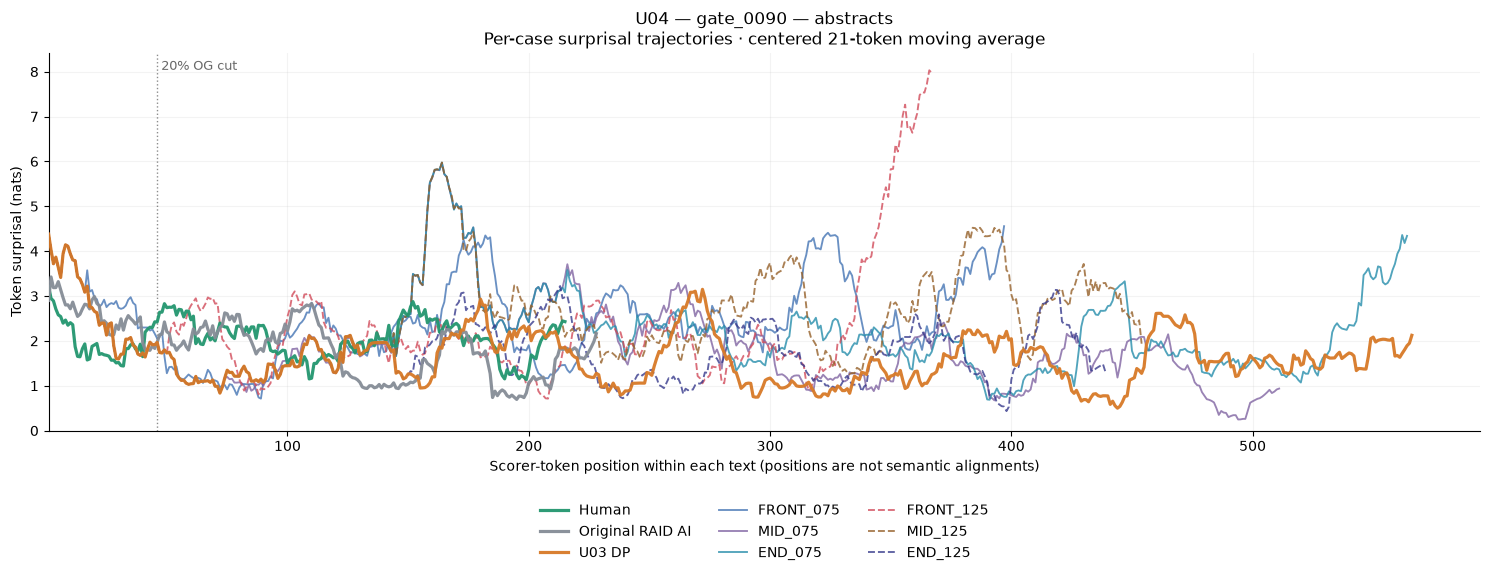

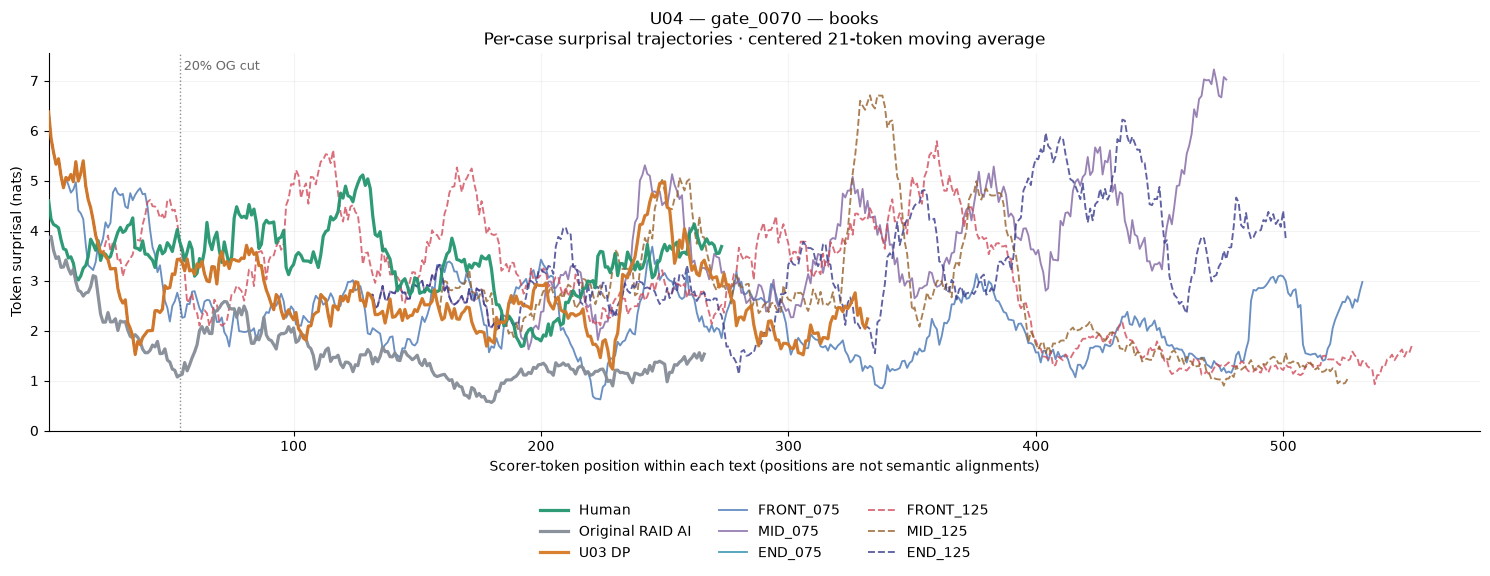

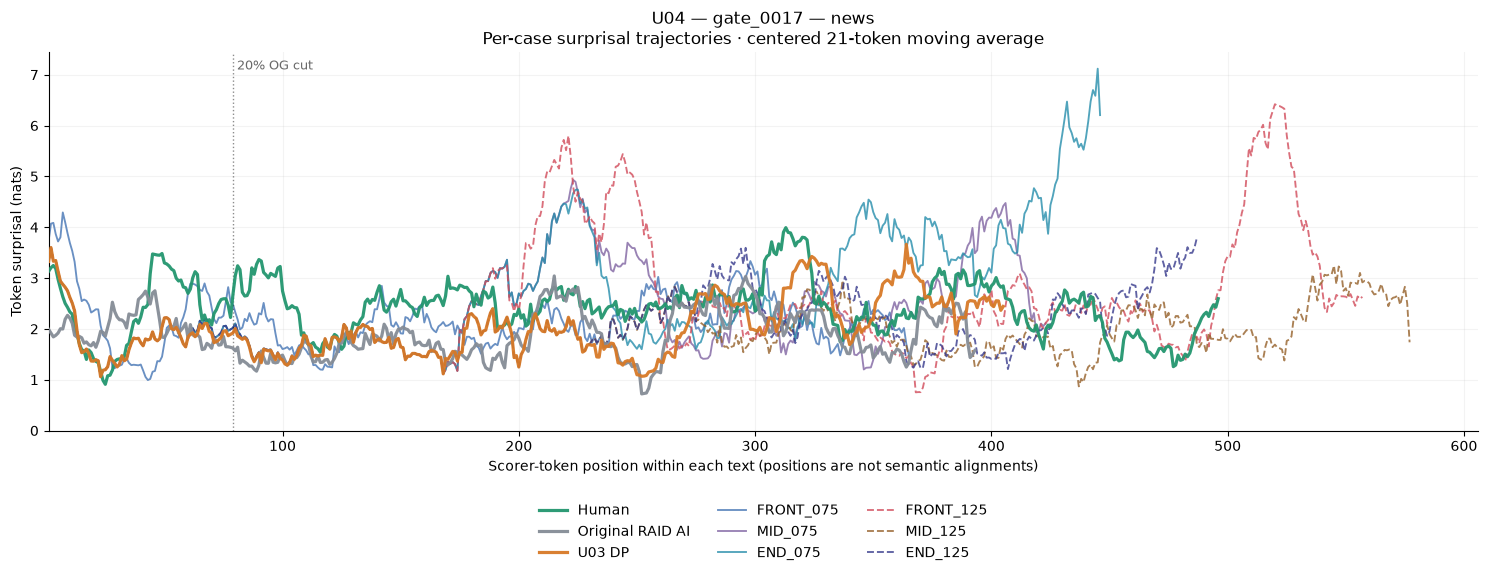

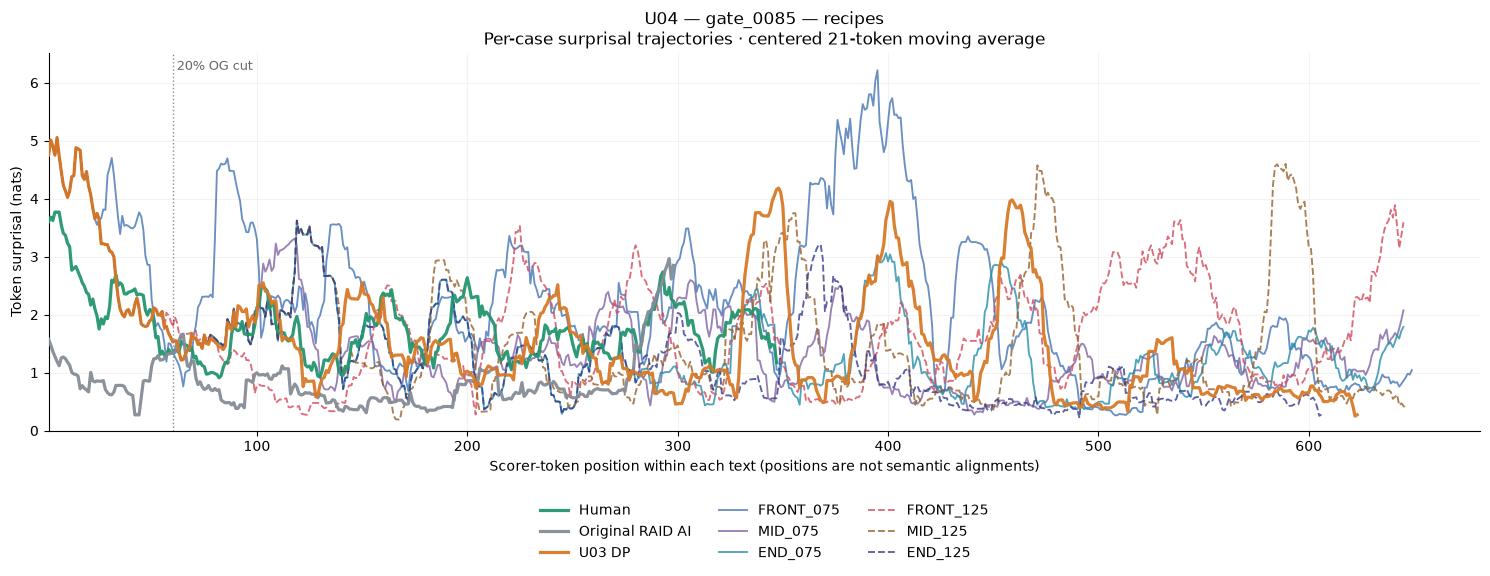

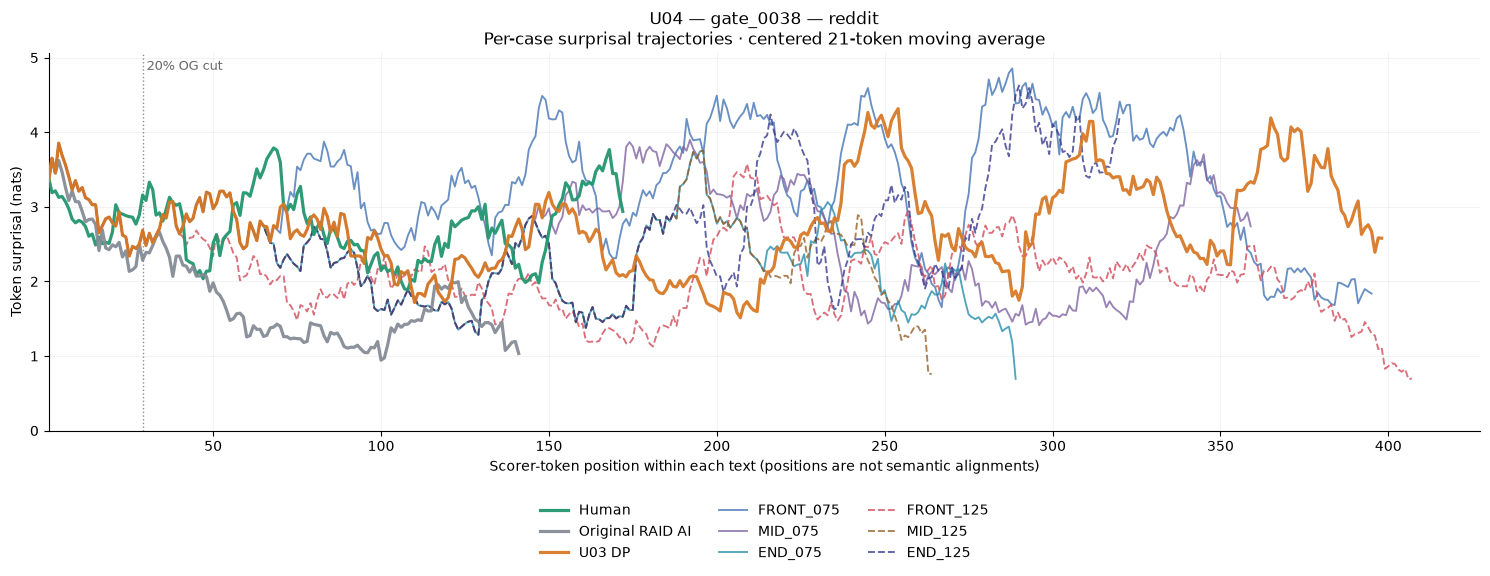

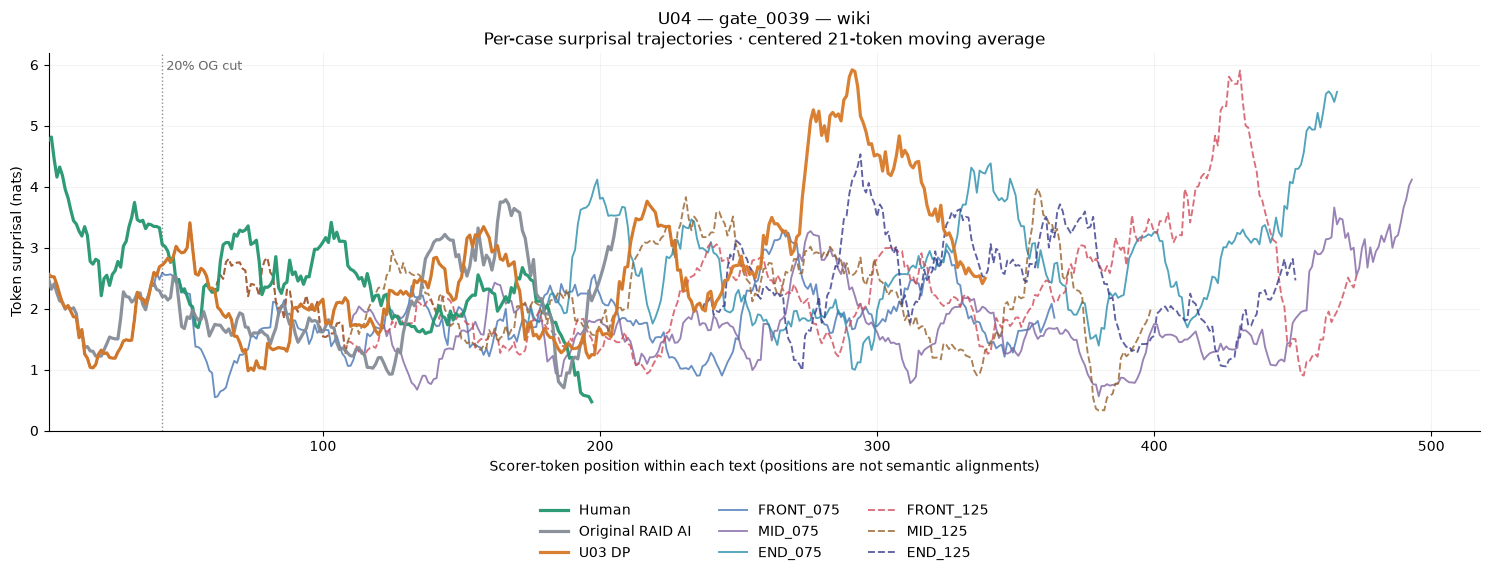

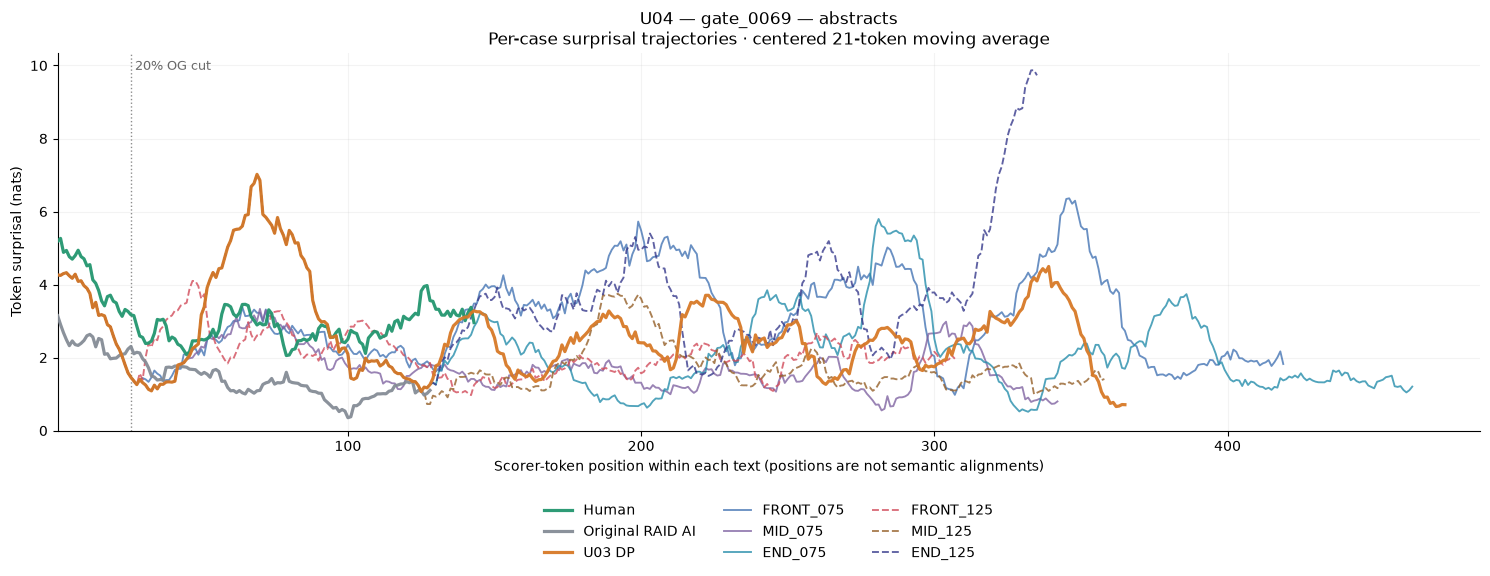

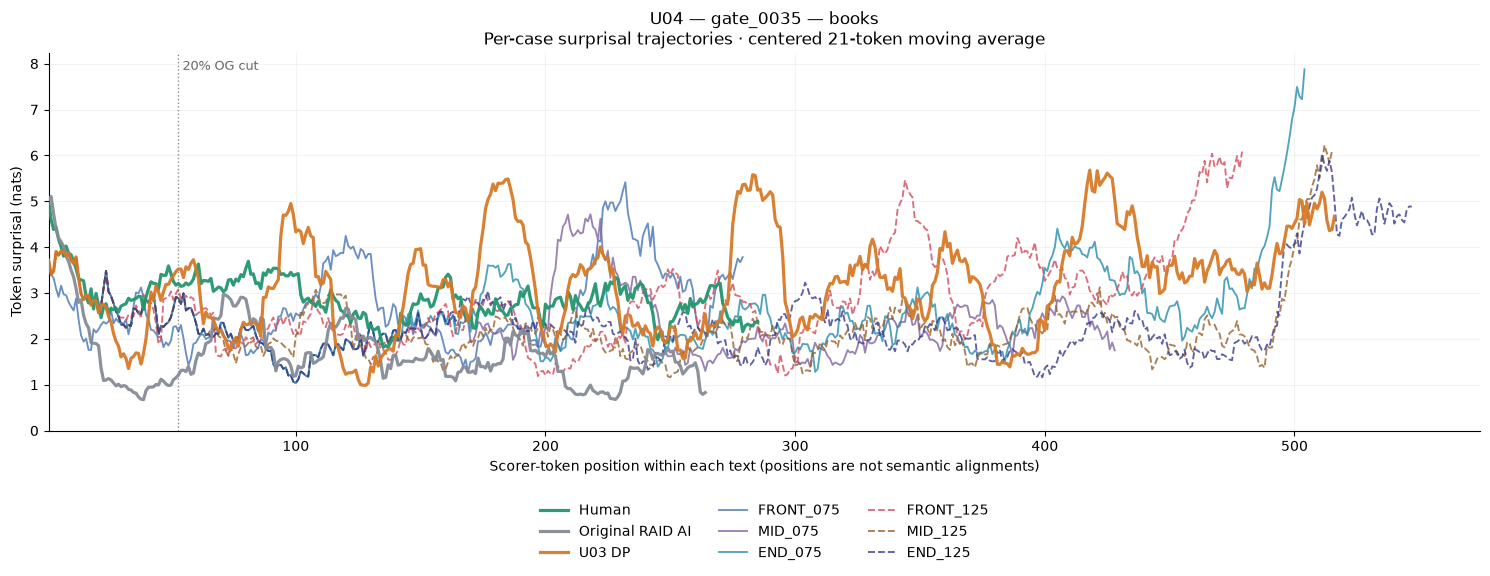

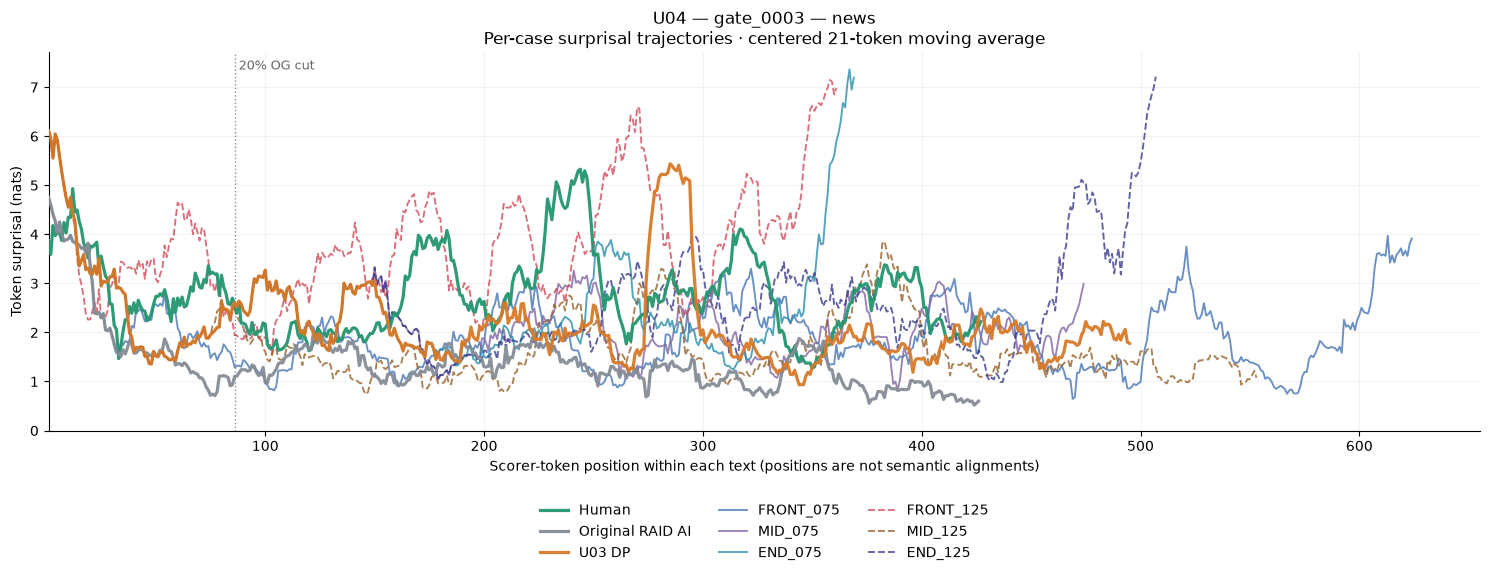

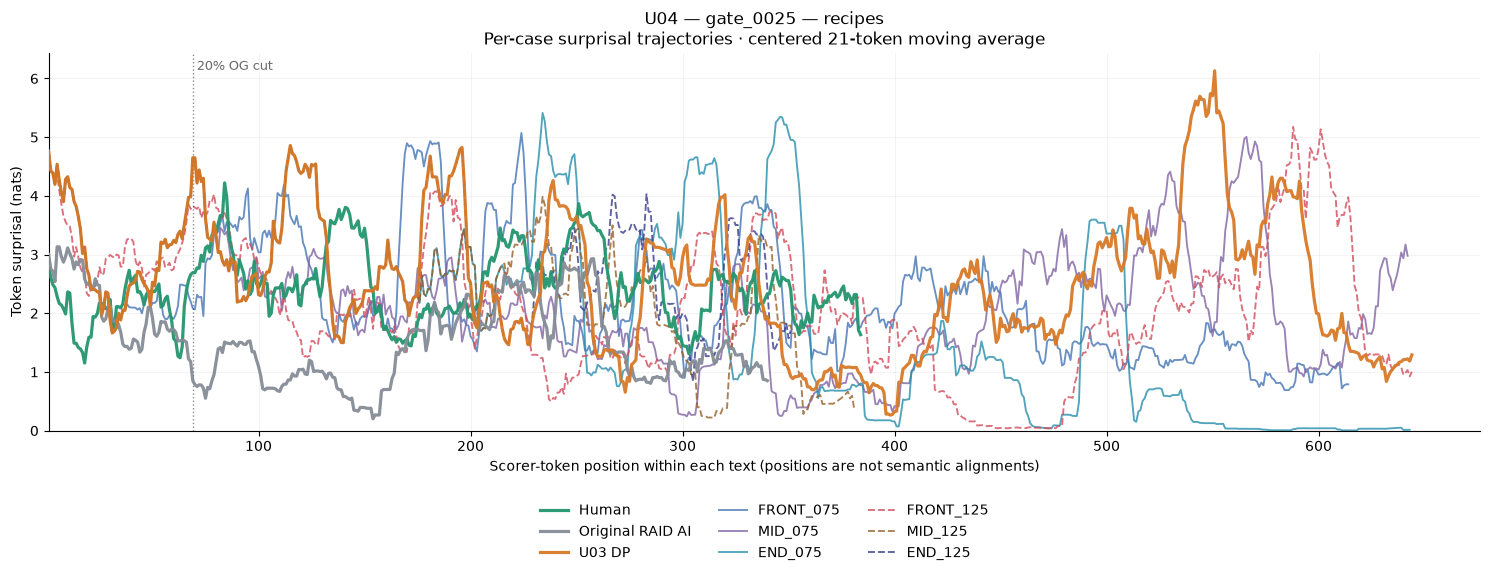

Saved per-case PDF/PNG plots: ../results/causal/U04_context_range_sweep_v1/frontloading_evaluation_v1/figures
Curves include the opening and stop at each text's available scoring endpoint.


In [9]:
# Per-case surprisal trajectories: all 9 conditions together.
# Reuses existing scores; no generation or rescoring.

SMOOTH_WINDOW = 21
SHOW_RAW_UNDERLAY = False

assert "LOSSES" in globals(), "Run the evaluation's cached-scoring cell first."
assert isinstance(SMOOTH_WINDOW, int) and SMOOTH_WINDOW >= 1

plot_dir = EVAL_DIR / "figures"
plot_dir.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

trajectory_rows = []
benchmarks = {"HUMAN", "OG", "DIRECT_PROMPT"}

for cid in CASES:
    domain = panel.loc[panel.case_id.eq(cid), "domain"].iloc[0]
    fig, ax = plt.subplots(figsize=(15, 6))

    for group in ORDER:
        raw = np.asarray(LOSSES[(cid, group)], dtype=float)

        # Loss index 0 predicts token position 1:
        # the first input token itself has no scored predecessor.
        positions = np.arange(1, len(raw) + 1)

        smooth = (
            pd.Series(raw)
            .rolling(
                window=SMOOTH_WINDOW,
                center=True,
                min_periods=1,
            )
            .mean()
            .to_numpy()
        )

        is_baseline = group in benchmarks
        linestyle = "--" if group.endswith("_125") else "-"
        linewidth = 2.3 if is_baseline else 1.35

        if SHOW_RAW_UNDERLAY and SMOOTH_WINDOW > 1:
            ax.plot(
                positions, raw,
                color=COLORS[group],
                linewidth=0.5,
                alpha=0.12,
            )

        ax.plot(
            positions, smooth,
            color=COLORS[group],
            linestyle=linestyle,
            linewidth=linewidth,
            alpha=0.95 if is_baseline else 0.8,
            label=LABELS[group],
            zorder=3 if is_baseline else 2,
        )

        trajectory_rows.extend(
            {
                "case_id": cid,
                "domain": domain,
                "group": group,
                "target_token_position": int(position),
                "surprisal_nats": float(value),
                "display_surprisal_nats": float(display_value),
                "smoothing_window": SMOOTH_WINDOW,
            }
            for position, value, display_value
            in zip(positions, raw, smooth)
        )

    # Display the earlier warmup boundary without discarding the opening.
    cut = int(np.ceil(
        WARMUP_FRACTION * len(TOKEN_IDS[(cid, "OG")])
    ))
    ax.axvline(cut, color="black", linestyle=":", linewidth=1, alpha=0.45)
    ax.text(
        cut, 0.98, " 20% OG cut",
        transform=ax.get_xaxis_transform(),
        va="top", fontsize=9, color="dimgray",
    )

    smoothing = (
        "raw token surprisal"
        if SMOOTH_WINDOW == 1
        else f"centered {SMOOTH_WINDOW}-token moving average"
    )

    ax.set_title(
        f"U04 — {cid} — {domain}\n"
        f"Per-case surprisal trajectories · {smoothing}"
    )
    ax.set_xlabel(
        "Scorer-token position within each text "
        "(positions are not semantic alignments)"
    )
    ax.set_ylabel("Token surprisal (nats)")
    ax.set_xlim(left=1)
    ax.set_ylim(bottom=0)
    ax.grid(alpha=0.15)
    ax.spines[["top", "right"]].set_visible(False)

    ax.legend(
        loc="upper center",
        bbox_to_anchor=(0.5, -0.16),
        ncol=3,
        frameon=False,
    )
    fig.tight_layout()

    filename = f"U04_{cid}_all_conditions_token_surprisal_w{SMOOTH_WINDOW}"
    for directory in (FIG_DIR, plot_dir):
        fig.savefig(directory / f"{filename}.pdf", bbox_inches="tight")
        fig.savefig(
            directory / f"{filename}.png",
            dpi=240, bbox_inches="tight",
        )

    plt.show()
    plt.close(fig)

pd.DataFrame(trajectory_rows).to_csv(
    EVAL_DIR / f"token_trajectories_w{SMOOTH_WINDOW}.csv",
    index=False,
)

print("Saved per-case PDF/PNG plots:", plot_dir)
print("Curves include the opening and stop at each text's available scoring endpoint.")

[1/100] gate_0090 | HUMAN | cached
[2/100] gate_0090 | OG | cached
[3/100] gate_0090 | DIRECT_PROMPT | cached
[4/100] gate_0090 | FRONT_075 | cached
[5/100] gate_0090 | MID_075 | cached
[6/100] gate_0070 | HUMAN | cached
[7/100] gate_0070 | OG | cached
[8/100] gate_0070 | DIRECT_PROMPT | cached
[9/100] gate_0070 | FRONT_075 | cached
[10/100] gate_0070 | MID_075 | cached
[11/100] gate_0017 | HUMAN | cached
[12/100] gate_0017 | OG | cached
[13/100] gate_0017 | DIRECT_PROMPT | cached
[14/100] gate_0017 | FRONT_075 | cached
[15/100] gate_0017 | MID_075 | cached
[16/100] gate_0085 | HUMAN | cached
[17/100] gate_0085 | OG | cached
[18/100] gate_0085 | DIRECT_PROMPT | cached
[19/100] gate_0085 | FRONT_075 | cached
[20/100] gate_0085 | MID_075 | cached
[21/100] gate_0038 | HUMAN | cached
[22/100] gate_0038 | OG | cached
[23/100] gate_0038 | DIRECT_PROMPT | cached
[24/100] gate_0038 | FRONT_075 | cached
[25/100] gate_0038 | MID_075 | cached
[26/100] gate_0039 | HUMAN | cached
[27/100] gate_0039

group,HUMAN,OG,DIRECT_PROMPT,FRONT_075,MID_075
case_id,,,,,
gate_0090,True,True,False,False,False
gate_0038,True,True,False,False,False
gate_0039,True,True,False,False,False
gate_0069,True,True,False,False,False
gate_0062,True,True,False,False,False
gate_0046,True,True,False,True,False


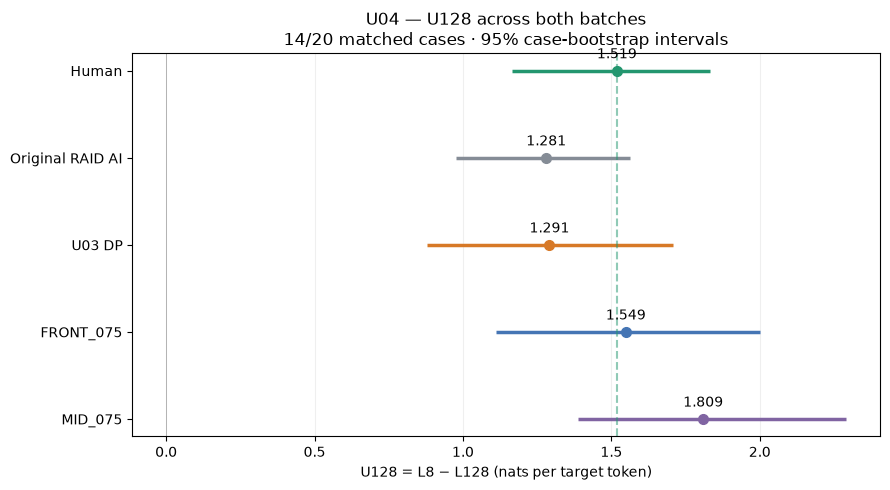

,group,cases,mean_U,ci_low,ci_high
0,HUMAN,14,1.5186,1.1639,1.8325
1,OG,14,1.2806,0.9778,1.5618
2,DIRECT_PROMPT,14,1.2915,0.8799,1.7080
3,FRONT_075,14,1.5487,1.1125,2.0014
4,MID_075,14,1.8095,1.3874,2.2905


,batch,arm,cases,mean_delta_U,ci_low,ci_high,increased,decreased
0,All 20,FRONT_075,14,0.2573,-0.3487,0.8190,9,5
1,All 20,MID_075,14,0.5180,-0.0389,0.9758,11,2
2,Initial 10,FRONT_075,6,1.0222,0.7004,1.4480,6,0
3,Initial 10,MID_075,6,1.2258,0.8700,1.6677,6,0
4,Additional 10,FRONT_075,8,-0.3164,-1.0681,0.4910,3,5
5,Additional 10,MID_075,8,-0.0129,-0.7006,0.4604,5,2


Saved: ../results/causal/U04_U128_all20_F75_M75_v1


In [10]:
# U128: all 20 cases, three benchmarks + FRONT_075 + MID_075.
# Run in U04_frontloading_evaluation.ipynb after its scoring setup.

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

assert all(x in globals() for x in (
    "escorer", "etok", "context_utility", "EVAL_SPEC",
    "fingerprint", "sha_text", "atomic_json"
)), "Load the existing U04 evaluation/scoring setup first."

groups20 = ["HUMAN", "OG", "DIRECT_PROMPT", "FRONT_075", "MID_075"]
batch_dirs = [
    ROOT / "results/causal/U04_context_range_sweep_v1",
    ROOT / "results/causal/U04_context_range_remaining10_F75_M75_v1",
]
out20 = ROOT / "results/causal/U04_U128_all20_F75_M75_v1"
cache20 = out20 / "cache"
cache20.mkdir(parents=True, exist_ok=True)

corpus20 = pd.read_parquet(
    ROOT / "results/causal/C02d2_fz118_ghostbuster_raid/paired_corpus.parquet"
)
cohort20 = pd.read_csv(
    ROOT / "results/causal/U01_temporal_method_selection/cohort20.csv",
    keep_default_na=False,
)
dp20 = pd.read_parquet(
    ROOT / "results/causal/U03_INFO_POOL_ALL20_GENERAL_v2/"
           "comparison_reused_u02/generations.parquet"
)
assert len(cohort20) == 20 and cohort20.case_id.nunique() == 20
case_order20 = cohort20.case_id.astype(str).tolist()

def source_key20(value):
    return str(value).split("raid:", 1)[-1]

human20 = corpus20.loc[corpus20.label.eq(0)].copy()
human20["_key"] = human20.source_id.map(source_key20)

# Recover exact saved texts and verify generation provenance.
text_rows20 = []
for batch_index, directory in enumerate(batch_dirs):
    contract20 = json.loads((directory / "contract.json").read_text())
    expected = case_order20[batch_index * 10:(batch_index + 1) * 10]
    assert contract20["cases"] == expected, "Unexpected batch membership/order."
    inputs20 = {x["case_id"]: x for x in contract20["case_inputs"]}
    provenance20 = {
        x["case_id"]: x for x in contract20["benchmark_provenance"]
    }

    for cid in expected:
        row = cohort20.loc[cohort20.case_id.astype(str).eq(cid)].iloc[0]
        frozen = inputs20[cid]
        assert str(row.source_id) == frozen["source_id"]
        assert sha_text(row.prompt) == frozen["task_sha"]

        ai = corpus20.loc[
            corpus20.label.eq(1)
            & corpus20.source_id.astype(str).eq(str(row.source_id))
        ]
        human = human20.loc[
            human20["_key"].eq(source_key20(row.source_id))
            & human20.domain.astype(str).eq(str(row.domain))
        ]
        dp = dp20.loc[
            dp20.case_id.astype(str).eq(cid)
            & dp20.arm.eq("DIRECT_PROMPT")
            & dp20.replicate.eq(0)
        ]
        assert len(ai) == len(human) == len(dp) == 1, cid
        texts = {
            "OG": str(ai.iloc[0].text),
            "HUMAN": str(human.iloc[0].text),
            "DIRECT_PROMPT": str(dp.iloc[0].generated_text),
        }
        assert sha_text(texts["OG"]) == frozen["previous_ai_sha"]
        assert sha_text(texts["DIRECT_PROMPT"]) == provenance20[cid]["dp_text_sha"]

        for arm in groups20[3:]:
            saved = json.loads(
                (directory / "runs" / f"{cid}__{arm}.json").read_text()
            )
            spec, summary = saved["spec"], saved["summary"]
            assert saved["record_sha"] == fingerprint({
                k: v for k, v in saved.items() if k != "record_sha"
            })
            assert spec["contract_sha"] == fingerprint(contract20)
            assert spec["case_id"] == cid and spec["arm"] == arm
            assert spec["previous_ai_sha"] == frozen["previous_ai_sha"]
            assert spec["task_sha"] == frozen["task_sha"]
            assert summary["stop_reason"] in {"eos", "truncated"}
            assert summary["text_sha"] == sha_text(summary["generated_text"])
            texts[arm] = summary["generated_text"]

        for group in groups20:
            text_rows20.append(dict(
                case_id=cid, group=group, batch=batch_index + 1,
                text=texts[group], text_sha=sha_text(texts[group]),
            ))

texts20 = pd.DataFrame(text_rows20)
assert len(texts20) == 100
assert not texts20.duplicated(["case_id", "group"]).any()
atomic_json(out20 / "text_manifest.json",
            texts20.drop(columns="text").to_dict("records"))

# Metric-specific cache contract; identical U128 protocol to the first batch.
assert TARGET_COUNT == 8
scoring20 = {
    key: EVAL_SPEC[key] for key in (
        "model", "revision", "dtype", "device_type",
        "torch", "transformers", "utility", "utility_batch",
    )
}
scoring20.update(k=128, targets=8, version="U128_all20_v1")
assert scoring20["utility_batch"] == UTILITY_BATCH_SIZE
assert getattr(escorer.config, "_commit_hash", None) == scoring20["revision"]

old_eval_dir20 = batch_dirs[0] / "frontloading_evaluation_v1"
old_contract20 = json.loads(
    (old_eval_dir20 / "evaluation_contract.json").read_text()
)
assert all(
    old_contract20[key] == scoring20[key]
    for key in (
        "model", "revision", "dtype", "device_type",
        "torch", "transformers", "utility", "utility_batch",
    )
), "Scorer settings differ from the first-batch evaluation."

score_rows20 = []
for i, row in enumerate(texts20.itertuples(index=False), 1):
    spec = dict(
        scoring=scoring20, text_sha=row.text_sha, kind="U128"
    )
    path = cache20 / f"{fingerprint(spec)}.json"
    reused = False

    if path.exists():
        saved = json.loads(path.read_text())
        assert saved["spec"] == spec
        assert saved["value_sha"] == fingerprint(saved["value"])
        value = saved["value"]
        reused = True
    else:
        old_spec = dict(
            evaluation_sha=fingerprint(old_contract20),
            text_sha=row.text_sha, kind="U128",
        )
        old_path = old_eval_dir20 / "cache" / f"{fingerprint(old_spec)}.json"
        if old_path.exists():
            saved = json.loads(old_path.read_text())
            assert saved["spec"] == old_spec
            assert saved["value_sha"] == fingerprint(saved["value"])
            value = saved["value"]
            reused = True
        else:
            ids = etok(row.text, add_special_tokens=False)["input_ids"]
            value = context_utility(ids, 128)

        atomic_json(path, dict(
            spec=spec, value=value, value_sha=fingerprint(value)
        ))

    score_rows20.append(dict(
        case_id=row.case_id, group=row.group, batch=row.batch,
        eligible=value["eligible"], U=value.get("U", np.nan),
    ))
    print(
        f"[{i}/100] {row.case_id} | {row.group} | "
        f"{'cached' if reused else 'scored'}",
        flush=True,
    )

scores20 = pd.DataFrame(score_rows20)
scores20.to_csv(out20 / "U128_by_case.csv", index=False)
wide20 = scores20.pivot(
    index="case_id", columns="group", values="U"
).reindex(index=case_order20, columns=groups20)

# Identical eligible cases for every line in the graph.
eligible20 = wide20.notna().all(axis=1)
excluded20 = wide20.loc[~eligible20]
if len(excluded20):
    print("Excluded from the matched comparison (<256 scorer tokens):")
    display(excluded20.isna().rename_axis("case_id"))
wide20 = wide20.loc[eligible20]
assert len(wide20), "No cases have U128 support across all five groups."

rng20 = np.random.default_rng(20260920)
values20 = wide20.to_numpy(dtype=float)
indices20 = rng20.integers(
    0, len(values20), size=(10000, len(values20))
)
boots20 = values20[indices20].mean(axis=1)
means20 = values20.mean(axis=0)
lo20, hi20 = np.quantile(boots20, [.025, .975], axis=0)

labels20 = ["Human", "Original RAID AI", "U03 DP", "FRONT_075", "MID_075"]
colors20 = ["#23966F", "#858C96", "#D77927", "#4575B4", "#8064A2"]
fig, ax = plt.subplots(figsize=(9, 5))
for j, (label, color) in enumerate(zip(labels20, colors20)):
    ax.hlines(j, lo20[j], hi20[j], color=color, lw=2.5)
    ax.plot(means20[j], j, "o", color=color, ms=7)
    ax.annotate(
        f"{means20[j]:.3f}", (means20[j], j),
        xytext=(0, 9), textcoords="offset points", ha="center",
    )
ax.axvline(means20[0], color=colors20[0], ls="--", alpha=.5)
ax.axvline(0, color="black", lw=.7, alpha=.25)
ax.set_yticks(range(5), labels20)
ax.invert_yaxis()
ax.set_xlabel("U128 = L8 − L128 (nats per target token)")
ax.set_title(
    f"U04 — U128 across both batches\n"
    f"{len(wide20)}/20 matched cases · 95% case-bootstrap intervals"
)
ax.grid(axis="x", alpha=.2)
fig.tight_layout()
for ext in ("png", "pdf"):
    fig.savefig(out20 / f"U04_U128_all20.{ext}", dpi=240, bbox_inches="tight")
plt.show()
plt.close(fig)

summary20 = pd.DataFrame(dict(
    group=groups20, cases=len(wide20), mean_U=means20,
    ci_low=lo20, ci_high=hi20,
))
summary20.to_csv(out20 / "U128_means.csv", index=False)
display(summary20.round(4))

# Paired changes: combined result plus separate exploratory/follow-up batches.
paired_rows20 = []
for batch_label, case_subset in [
    ("All 20", case_order20),
    ("Initial 10", case_order20[:10]),
    ("Additional 10", case_order20[10:]),
]:
    subset = wide20.loc[wide20.index.isin(case_subset)]
    if subset.empty:
        continue
    for arm in groups20[3:]:
        delta = (subset[arm] - subset["DIRECT_PROMPT"]).to_numpy()
        rng = np.random.default_rng(20260920)
        boot = delta[rng.integers(
            0, len(delta), size=(10000, len(delta))
        )].mean(axis=1)
        low, high = np.quantile(boot, [.025, .975])
        paired_rows20.append(dict(
            batch=batch_label, arm=arm, cases=len(delta),
            mean_delta_U=delta.mean(), ci_low=low, ci_high=high,
            increased=int((delta > 0).sum()),
            decreased=int((delta < 0).sum()),
        ))
paired20 = pd.DataFrame(paired_rows20)
paired20.to_csv(out20 / "U128_paired_vs_DP.csv", index=False)
display(paired20.round(4))
print("Saved:", out20)

In [11]:
# from pathlib import Path
# import json
# import pandas as pd

# root = Path(ROOT)
# cohort_print = pd.read_csv(
#     root / "results/causal/U01_temporal_method_selection/cohort20.csv",
#     keep_default_na=False,
# )
# run_dirs = [
#     root / "results/causal/U04_context_range_sweep_v1/runs",
#     root / "results/causal/U04_context_range_remaining10_F75_M75_v1/runs",
# ]

# assert len(cohort_print) == 20
# assert cohort_print.case_id.nunique() == 20

# # Check all files before printing.
# to_print = []
# for row in cohort_print.itertuples(index=False):
#     cid = str(row.case_id)
#     matches = [
#         directory / f"{cid}__MID_075.json"
#         for directory in run_dirs
#         if (directory / f"{cid}__MID_075.json").exists()
#     ]
#     assert len(matches) == 1, f"{cid}: expected one saved M75 result."
#     saved = json.loads(matches[0].read_text())
#     assert saved["spec"]["case_id"] == cid
#     assert saved["spec"]["arm"] == "MID_075"
#     summary = saved["summary"]
#     assert summary["stop_reason"] in {"eos", "truncated"}
#     to_print.append((row, summary))

# for i, (row, summary) in enumerate(to_print, 1):
#     print("\n" + "=" * 100)
#     print(f"{i:02d}/20 | {row.case_id} | {row.domain} | MID_075")
#     print(
#         f"Stop: {summary['stop_reason']} | "
#         f"Words: {summary.get('word_count', '?')} | "
#         f"Rewinds: {summary.get('coherence_rewinds', '?')}"
#     )
#     print("=" * 100)
#     print("\nORIGINAL TASK:\n")
#     print(row.prompt)
#     print("\nM75 REWRITE:\n")
#     print(summary["generated_text"])

# print("\nPrinted all 20 M75 cases.")


01/20 | gate_0090 | abstracts | MID_075
Stop: eos | Words: 351 | Rewinds: 0

ORIGINAL TASK:

Write the abstract for the academic paper titled "Uncertainty-aware Self-ensembling Model for Semi-supervised 3D Left Atrium Segmentation".

M75 REWRITE:

Title: Uncertainty-aware Self-ensembling Model for Semi-supervised 3D Left Atrium Segmentation

Abstract:

The accurate segmentation of 3D left atrium structures is crucial in clinical settings for optimal patient care and treatment planning. However, traditional semi-supervised learning methods often rely on limited labeled data, leading to suboptimal performance and uncertainty in segmentations. To address these challenges, we present the Uncertainty-aware Self-ensembling Model (UA-SE), which leverages the correlations between neighboring voxels and self-ensembling strategy to enhance the representation power of semi-supervised learning for 3D left atrium segmentation.

At the Medical Image Analysis Group (MIAG) of the German Cancer Resear

[1/162] gate_0001 | HUMAN | scored
[2/162] gate_0001 | OG | scored
[3/162] gate_0001 | MID_075 | scored
[4/162] gate_0003 | HUMAN | cached
[5/162] gate_0003 | OG | cached
[6/162] gate_0003 | MID_075 | cached
[7/162] gate_0004 | HUMAN | scored
[8/162] gate_0004 | OG | scored
[9/162] gate_0004 | MID_075 | scored
[10/162] gate_0005 | HUMAN | scored
[11/162] gate_0005 | OG | scored
[12/162] gate_0005 | MID_075 | scored
[13/162] gate_0007 | HUMAN | scored
[14/162] gate_0007 | OG | scored
[15/162] gate_0007 | MID_075 | scored
[16/162] gate_0015 | HUMAN | scored
[17/162] gate_0015 | OG | scored
[18/162] gate_0015 | MID_075 | scored
[19/162] gate_0016 | HUMAN | cached
[20/162] gate_0016 | OG | cached
[21/162] gate_0016 | MID_075 | cached
[22/162] gate_0017 | HUMAN | cached
[23/162] gate_0017 | OG | cached
[24/162] gate_0017 | MID_075 | cached
[25/162] gate_0018 | HUMAN | cached
[26/162] gate_0018 | OG | cached
[27/162] gate_0018 | MID_075 | cached
[28/162] gate_0019 | HUMAN | scored
[29/162] g

group,HUMAN,OG,MID_075
case_id,,,
gate_0001,True,True,False
gate_0005,True,True,True
gate_0019,True,True,False
gate_0022,True,True,False
gate_0026,True,True,False
gate_0038,True,True,False
gate_0039,True,True,False
gate_0046,True,True,False
gate_0047,True,True,False


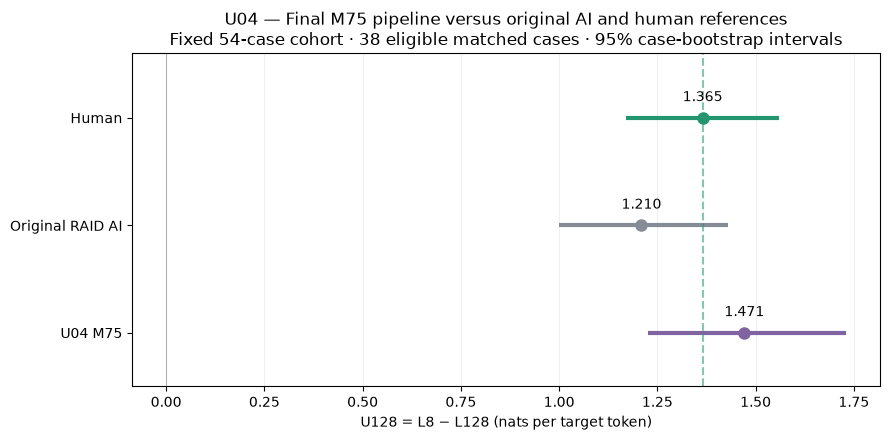

,group,cases,mean_U,ci_low,ci_high
0,HUMAN,38,1.3652,1.1701,1.5589
1,OG,38,1.2096,0.9991,1.4289
2,MID_075,38,1.4714,1.2259,1.7300


,sample,cases,increased,decreased,unchanged,positive_fraction,median_delta_U,mean_delta_U,ci_low,ci_high
0,Three-group matched,38,21,17,0,0.5526,0.1033,0.2619,0.0022,0.5385
1,All eligible M75–OG pairs,40,21,19,0,0.5250,0.0901,0.1929,-0.0792,0.4705


All saved M75 outputs retained, including token-capped outputs.
Intervals describe case variability, not variability across generation seeds.
Saved final U04 results: ../results/causal/U04_M75_final54_U128_v1


In [6]:
# U04 final: fixed 54 cases — HUMAN vs original RAID AI vs M75.
# Requires the existing Qwen evaluation setup and context_utility().
# No generation. Each newly computed U128 score is saved immediately.

import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

assert all(name in globals() for name in (
    "escorer", "etok", "context_utility", "EVAL_SPEC",
    "fingerprint", "sha_text", "atomic_json",
)), "Load the U04 Qwen evaluation setup first."
assert TARGET_COUNT == 8
assert UTILITY_BATCH_SIZE == EVAL_SPEC["utility_batch"]
assert getattr(escorer.config, "_commit_hash", None) == EVAL_SPEC["revision"]

final_dir = ROOT / "results/causal/U04_M75_final54_U128_v1"
final_cache = final_dir / "cache"
final_cache.mkdir(parents=True, exist_ok=True)
figure_dir = ROOT / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)

generation_dirs = [
    ROOT / "results/causal/U04_context_range_sweep_v1",
    ROOT / "results/causal/U04_context_range_remaining10_F75_M75_v1",
    ROOT / "results/causal/U04_M75_remaining34_v1",
]
groups = ["HUMAN", "OG", "MID_075"]
labels = ["Human", "Original RAID AI", "U04 M75"]
colors = ["#23966F", "#858C96", "#8064A2"]

fixed = pd.read_parquet(
    ROOT / "results/causal/U00_soft_history_bruteforce/fixed54_prompts.parquet"
)
fixed["case_id"] = fixed.case_id.astype(str)
assert len(fixed) == 54 and fixed.case_id.is_unique
case_order = fixed.case_id.tolist()

corpus_final = pd.read_parquet(
    ROOT / "results/causal/C02d2_fz118_ghostbuster_raid/paired_corpus.parquet"
)
human_final = corpus_final.loc[corpus_final.label.eq(0)].copy()
human_final["_source_key"] = human_final.source_id.astype(str).map(
    lambda x: x.split("raid:", 1)[-1]
)

# Recover all 54 saved M75 outputs and validate their checkpoint checksums.
saved_runs = {}
for directory in generation_dirs:
    contract_final = json.loads((directory / "contract.json").read_text())
    assert list(contract_final["arms"]["MID_075"]) == [1.0, 0.75, 1.0]
    for cid in contract_final["cases"]:
        assert cid not in saved_runs, f"Duplicate M75 case: {cid}"
        path = directory / "runs" / f"{cid}__MID_075.json"
        saved = json.loads(path.read_text())
        assert saved["record_sha"] == fingerprint({
            k: v for k, v in saved.items() if k != "record_sha"
        }), path
        assert saved["spec"]["contract_sha"] == fingerprint(contract_final)
        assert saved["spec"]["case_id"] == cid
        assert saved["spec"]["arm"] == "MID_075"
        assert saved["summary"]["stop_reason"] in {"eos", "truncated"}
        assert saved["summary"]["text_sha"] == sha_text(
            saved["summary"]["generated_text"]
        )
        saved_runs[cid] = saved

assert set(saved_runs) == set(case_order), "Saved M75 cases differ from fixed54."

text_records = []
for row in fixed.itertuples(index=False):
    cid = row.case_id
    ai = corpus_final.loc[
        corpus_final.label.eq(1)
        & corpus_final.source_id.astype(str).eq(str(row.source_id))
    ]
    human = human_final.loc[
        human_final["_source_key"].eq(str(row.source_id).split("raid:", 1)[-1])
        & human_final.domain.astype(str).eq(str(row.domain))
    ]
    assert len(ai) == len(human) == 1, f"Reference ambiguity: {cid}"
    saved = saved_runs[cid]
    assert saved["spec"]["task_sha"] == sha_text(row.prompt)
    assert saved["spec"]["previous_ai_sha"] == sha_text(ai.iloc[0].text)

    texts = {
        "HUMAN": str(human.iloc[0].text),
        "OG": str(ai.iloc[0].text),
        "MID_075": saved["summary"]["generated_text"],
    }
    for group, text in texts.items():
        assert text.strip()
        text_records.append(dict(
            case_id=cid, domain=str(row.domain), group=group,
            text=text, text_sha=sha_text(text),
            stop_reason=(
                saved["summary"]["stop_reason"]
                if group == "MID_075" else "reference"
            ),
        ))

final_panel = pd.DataFrame(text_records)
assert len(final_panel) == 162

# Same metric-specific cache specification as the all-20 evaluation.
scoring_spec = {
    key: EVAL_SPEC[key] for key in (
        "model", "revision", "dtype", "device_type",
        "torch", "transformers", "utility", "utility_batch",
    )
}
scoring_spec.update(k=128, targets=8, version="U128_all20_v1")
all20_cache = ROOT / "results/causal/U04_U128_all20_F75_M75_v1/cache"
old_eval = generation_dirs[0] / "frontloading_evaluation_v1"
old_contract = json.loads((old_eval / "evaluation_contract.json").read_text())
assert all(
    old_contract[key] == scoring_spec[key]
    for key in (
        "model", "revision", "dtype", "device_type",
        "torch", "transformers", "utility", "utility_batch",
    )
), "Use the same scorer settings as the earlier U04 evaluation."

manifest = final_panel.drop(columns="text").to_dict("records")
final_contract = dict(
    cases=case_order, groups=groups, scoring=scoring_spec,
    manifest_sha=fingerprint(manifest),
    eligibility="At least 256 scorer tokens in all three groups",
    bootstrap_seed=20260920, bootstrap_replicates=10000,
)
contract_path = final_dir / "evaluation_contract.json"
if contract_path.exists():
    assert json.loads(contract_path.read_text()) == final_contract
else:
    atomic_json(contract_path, final_contract)
atomic_json(final_dir / "text_manifest.json", manifest)

score_records = []
for i, row in enumerate(final_panel.itertuples(index=False), 1):
    spec = dict(scoring=scoring_spec, text_sha=row.text_sha, kind="U128")
    cache_path = final_cache / f"{fingerprint(spec)}.json"
    prior_spec = dict(
        evaluation_sha=fingerprint(old_contract),
        text_sha=row.text_sha, kind="U128",
    )
    candidates = [
        (cache_path, spec),
        (all20_cache / f"{fingerprint(spec)}.json", spec),
        (old_eval / "cache" / f"{fingerprint(prior_spec)}.json", prior_spec),
    ]

    value = None
    for path, expected_spec in candidates:
        if path.exists():
            record = json.loads(path.read_text())
            assert record["spec"] == expected_spec, path
            assert record["value_sha"] == fingerprint(record["value"]), path
            value = record["value"]
            break

    cached = value is not None
    if not cached:
        ids = etok(row.text, add_special_tokens=False)["input_ids"]
        value = context_utility(ids, 128)

    if not cache_path.exists():
        atomic_json(cache_path, dict(
            spec=spec, value=value, value_sha=fingerprint(value)
        ))
    score_records.append(dict(
        case_id=row.case_id, domain=row.domain, group=row.group,
        stop_reason=row.stop_reason,
        eligible=value["eligible"], U=value.get("U", np.nan),
    ))
    print(
        f"[{i}/162] {row.case_id} | {row.group} | "
        f"{'cached' if cached else 'scored'}",
        flush=True,
    )

final_scores = pd.DataFrame(score_records)
final_scores.to_csv(final_dir / "U128_by_case.csv", index=False)

wide = final_scores.pivot(
    index="case_id", columns="group", values="U"
).reindex(index=case_order, columns=groups)
missing = wide.isna()
missing.to_csv(final_dir / "U128_missing_by_case.csv")
matched = wide.loc[~missing.any(axis=1)]
assert len(matched), "No cases meet the common U128 length requirement."

print(f"\nScored all 54 cases; matched three-group U128 sample: {len(matched)}/54.")
if missing.any(axis=1).any():
    print("Excluded cases — True indicates insufficient length for U128:")
    display(missing.loc[missing.any(axis=1)])

# Paired bootstrap: resample case rows jointly across all groups.
rng = np.random.default_rng(20260920)
values = matched.to_numpy(dtype=float)
indices = rng.integers(0, len(values), size=(10000, len(values)))
boots = values[indices].mean(axis=1)
means = values.mean(axis=0)
low, high = np.quantile(boots, [.025, .975], axis=0)

summary = pd.DataFrame(dict(
    group=groups, cases=len(matched), mean_U=means,
    ci_low=low, ci_high=high,
))
summary.to_csv(final_dir / "U128_group_summary.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 4.5))
for j, color in enumerate(colors):
    ax.hlines(j, low[j], high[j], color=color, linewidth=3)
    ax.plot(means[j], j, "o", color=color, markersize=8)
    ax.annotate(
        f"{means[j]:.3f}", (means[j], j),
        xytext=(0, 12), textcoords="offset points", ha="center",
    )
ax.axvline(means[0], color=colors[0], linestyle="--", alpha=.55)
ax.axvline(0, color="black", linewidth=.8, alpha=.25)
ax.set_yticks(range(3), labels)
ax.set_ylim(2.5, -.6)
ax.set_xlabel("U128 = L8 − L128 (nats per target token)")
ax.set_title(
    "U04 — Final M75 pipeline versus original AI and human references\n"
    f"Fixed 54-case cohort · {len(matched)} eligible matched cases · "
    "95% case-bootstrap intervals"
)
ax.grid(axis="x", alpha=.2)
fig.tight_layout()
for folder in (final_dir, figure_dir):
    for extension in ("png", "pdf"):
        fig.savefig(
            folder / f"U04_final54_U128.{extension}",
            dpi=300, bbox_inches="tight",
        )
plt.show()
plt.close(fig)
display(summary.round(4))

# Report direction counts, medians, and means, including the larger
# M75/OG pairwise sample when only the human reference is too short.
comparison_rows = []
comparison_cases = []
for sample, frame in [
    ("Three-group matched", matched),
    ("All eligible M75–OG pairs", wide[["OG", "MID_075"]].dropna()),
]:
    delta = (frame["MID_075"] - frame["OG"]).to_numpy()
    if not len(delta):
        continue
    rng = np.random.default_rng(20260920)
    boot_delta = delta[
        rng.integers(0, len(delta), size=(10000, len(delta)))
    ].mean(axis=1)
    lo, hi = np.quantile(boot_delta, [.025, .975])
    comparison_rows.append(dict(
        sample=sample, cases=len(delta),
        increased=int((delta > 0).sum()),
        decreased=int((delta < 0).sum()),
        unchanged=int((delta == 0).sum()),
        positive_fraction=float((delta > 0).mean()),
        median_delta_U=float(np.median(delta)),
        mean_delta_U=float(delta.mean()), ci_low=lo, ci_high=hi,
    ))
    comparison_cases.extend(
        dict(sample=sample, case_id=cid, delta_U=float(d))
        for cid, d in zip(frame.index, delta)
    )

comparison = pd.DataFrame(comparison_rows)
comparison.to_csv(final_dir / "U128_M75_vs_OG.csv", index=False)
pd.DataFrame(comparison_cases).to_csv(
    final_dir / "U128_M75_vs_OG_by_case.csv", index=False
)
display(comparison.round(4))
print("All saved M75 outputs retained, including token-capped outputs.")
print("Intervals describe case variability, not variability across generation seeds.")
print("Saved final U04 results:", final_dir)

Canonical NFZ source: ../results/causal/C04c_CARDINAL_controlled_insertion/16d25f12a76b/texts_after_CARDINAL_step10.csv
[1/54] gate_0001 | NFZ | scored
[2/54] gate_0003 | NFZ | scored
[3/54] gate_0004 | NFZ | scored
[4/54] gate_0005 | NFZ | scored
[5/54] gate_0007 | NFZ | scored
[6/54] gate_0015 | NFZ | scored
[7/54] gate_0016 | NFZ | scored
[8/54] gate_0017 | NFZ | scored
[9/54] gate_0018 | NFZ | scored
[10/54] gate_0019 | NFZ | scored
[11/54] gate_0020 | NFZ | scored
[12/54] gate_0021 | NFZ | scored
[13/54] gate_0022 | NFZ | scored
[14/54] gate_0023 | NFZ | scored
[15/54] gate_0024 | NFZ | scored
[16/54] gate_0025 | NFZ | scored
[17/54] gate_0026 | NFZ | scored
[18/54] gate_0027 | NFZ | scored
[19/54] gate_0028 | NFZ | scored
[20/54] gate_0030 | NFZ | scored
[21/54] gate_0035 | NFZ | scored
[22/54] gate_0037 | NFZ | scored
[23/54] gate_0038 | NFZ | scored
[24/54] gate_0039 | NFZ | scored
[25/54] gate_0046 | NFZ | scored
[26/54] gate_0047 | NFZ | scored
[27/54] gate_0048 | NFZ | score

group,HUMAN,OG,NFZ,MID_075
case_id,,,,
gate_0001,True,True,True,False
gate_0005,True,True,True,True
gate_0015,False,False,True,False
gate_0019,True,True,True,False
gate_0022,True,True,True,False
gate_0026,True,True,True,False
gate_0027,False,False,True,False
gate_0028,False,False,True,False
gate_0038,True,True,True,False


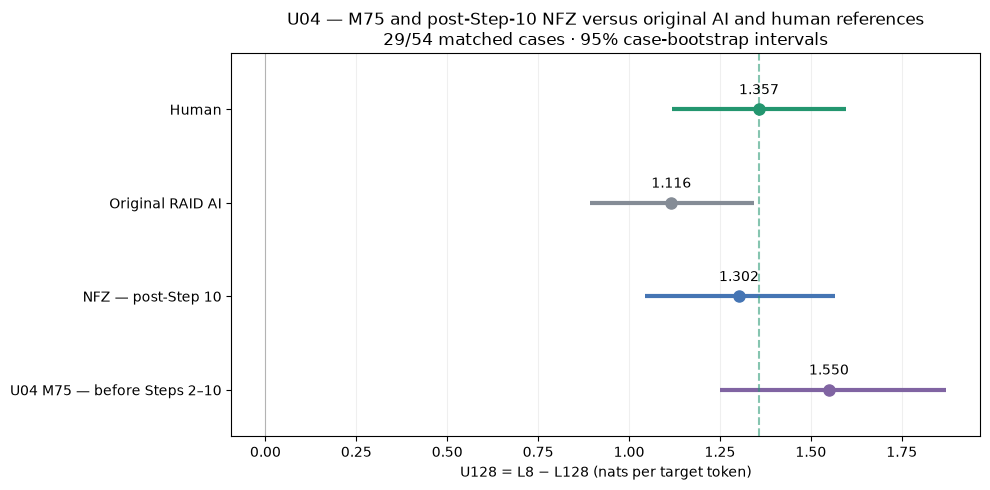

,group,cases,mean_U,ci_low,ci_high
0,HUMAN,29,1.3574,1.1182,1.5960
1,OG,29,1.1162,0.8935,1.3430
2,NFZ,29,1.3024,1.0429,1.5671
3,MID_075,29,1.5497,1.2508,1.8716


,sample,comparison,cases,increased,decreased,unchanged,positive_fraction,mean_gain,mean_loss_magnitude,total_gain,total_loss_magnitude,median_delta_U,mean_delta_U,ci_low,ci_high
0,Four-group matched,NFZ minus OG,29,16,13,0,0.5517,0.8795,0.6672,14.0724,8.6740,0.1878,0.1862,-0.1599,0.5264
1,Four-group matched,MID_075 minus OG,29,17,12,0,0.5862,0.9267,0.2652,15.7537,3.1824,0.1227,0.4335,0.1592,0.7304
2,Four-group matched,MID_075 minus NFZ,29,16,13,0,0.5517,1.0447,0.7340,16.7154,9.5425,0.3589,0.2473,-0.1271,0.6294
3,All eligible pairs,NFZ minus OG,30,16,14,0,0.5333,0.8795,0.6199,14.0724,8.6782,0.1813,0.1798,-0.1523,0.5249
4,All eligible pairs,MID_075 minus OG,40,21,19,0,0.5250,0.8310,0.5125,17.4513,9.7371,0.0901,0.1929,-0.0792,0.4705
5,All eligible pairs,MID_075 minus NFZ,31,16,15,0,0.5161,1.0447,0.8159,16.7154,12.2392,0.1593,0.1444,-0.2391,0.5257


NFZ is the historical post-Step-10 pipeline.
M75 has not undergone Steps 2–10; this is a pipeline comparison.
Saved: ../results/causal/U04_final54_U128_with_NFZ_v1


In [7]:
# Add canonical post-Step-10 NFZ to the final U04 U128 comparison.
# Run after the final-54 evaluation cell; Qwen must remain loaded.

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

assert all(name in globals() for name in (
    "final_scores", "fixed", "scoring_spec", "context_utility",
    "escorer", "etok", "fingerprint", "atomic_json", "sha_text"
)), "Run the final-54 evaluation setup first."

assert TARGET_COUNT == 8
assert UTILITY_BATCH_SIZE == scoring_spec["utility_batch"]
assert getattr(escorer.config, "_commit_hash", None) == scoring_spec["revision"]

nfz_out = ROOT / "results/causal/U04_final54_U128_with_NFZ_v1"
nfz_cache = nfz_out / "cache"
nfz_cache.mkdir(parents=True, exist_ok=True)
(ROOT / "figures").mkdir(parents=True, exist_ok=True)

# Use the exact NFZ input recorded by the frozen C05 evaluation.
c05_contract_path = (
    ROOT / "results/causal/C05_Ghostbuster_RAID_fixed54/contract.json"
)
if c05_contract_path.exists():
    c05_contract = json.loads(c05_contract_path.read_text())
    nfz_path = ROOT / c05_contract["NFZ_input"]
else:
    # Same canonical-run identification used in C05.
    candidates = []
    step10_root = ROOT / "results/causal/C04c_CARDINAL_controlled_insertion"
    for directory in sorted(step10_root.glob("*")):
        summary_path = directory / "stage_summary.csv"
        text_path = directory / "texts_after_CARDINAL_step10.csv"
        if not summary_path.exists() or not text_path.exists():
            continue
        last = pd.read_csv(summary_path).iloc[-1]
        if (
            np.isclose(float(last.AUROC), .671326, atol=5e-6, rtol=0)
            and np.isclose(
                float(last.mean_AI_score), .476821, atol=5e-6, rtol=0
            )
        ):
            candidates.append(text_path)
    assert len(candidates) == 1, f"Ambiguous NFZ endpoint: {candidates}"
    nfz_path = candidates[0]

nfz = pd.read_csv(nfz_path, keep_default_na=False)
nfz["case_id"] = nfz.case_id.astype(str)
assert len(nfz) == 54 and nfz.case_id.is_unique
assert set(nfz.case_id) == set(fixed.case_id.astype(str))
nfz = nfz.set_index("case_id").loc[fixed.case_id.astype(str)].reset_index()

fixed_index = fixed.set_index("case_id")
for row in nfz.itertuples(index=False):
    reference = fixed_index.loc[row.case_id]
    assert str(row.source_id) == str(reference.source_id), row.case_id
    assert str(row.domain) == str(reference.domain), row.case_id
    assert isinstance(row.text, str) and row.text.strip(), row.case_id

nfz_manifest = [
    dict(case_id=r.case_id, source_id=str(r.source_id),
         text_sha=sha_text(r.text))
    for r in nfz.itertuples(index=False)
]
comparison_contract = dict(
    scoring=scoring_spec,
    NFZ_input=str(nfz_path),
    NFZ_manifest=nfz_manifest,
    existing_scores_sha=fingerprint(
        final_scores.sort_values(["case_id", "group"]).to_dict("records")
    ),
)
contract_path = nfz_out / "comparison_contract.json"
if contract_path.exists():
    assert json.loads(contract_path.read_text()) == comparison_contract
else:
    atomic_json(contract_path, comparison_contract)

print("Canonical NFZ source:", nfz_path)
nfz_rows = []
for i, row in enumerate(nfz.itertuples(index=False), 1):
    spec = dict(
        scoring=scoring_spec, text_sha=sha_text(row.text), kind="U128"
    )
    path = nfz_cache / f"{fingerprint(spec)}.json"

    if path.exists():
        record = json.loads(path.read_text())
        assert record["spec"] == spec
        assert record["value_sha"] == fingerprint(record["value"])
        value = record["value"]
        status = "cached"
    else:
        ids = etok(row.text, add_special_tokens=False)["input_ids"]
        value = context_utility(ids, 128)
        atomic_json(path, dict(
            spec=spec, value=value, value_sha=fingerprint(value)
        ))
        status = "scored"

    nfz_rows.append(dict(
        case_id=row.case_id, domain=row.domain, group="NFZ",
        eligible=value["eligible"], U=value.get("U", np.nan),
    ))
    print(f"[{i}/54] {row.case_id} | NFZ | {status}", flush=True)

combined = pd.concat([
    final_scores.loc[
        final_scores.group.isin(["HUMAN", "OG", "MID_075"]),
        ["case_id", "domain", "group", "eligible", "U"],
    ],
    pd.DataFrame(nfz_rows),
], ignore_index=True)
assert len(combined) == 216
assert not combined.duplicated(["case_id", "group"]).any()
combined.to_csv(nfz_out / "U128_by_case.csv", index=False)

order = ["HUMAN", "OG", "NFZ", "MID_075"]
labels = [
    "Human",
    "Original RAID AI",
    "NFZ — post-Step 10",
    "U04 M75 — before Steps 2–10",
]
colors = ["#23966F", "#858C96", "#4575B4", "#8064A2"]
all_wide = combined.pivot(
    index="case_id", columns="group", values="U"
).reindex(index=fixed.case_id.astype(str), columns=order)

missing = all_wide.isna()
missing.to_csv(nfz_out / "U128_missing_by_case.csv")
common = all_wide.dropna()
assert len(common), "No cases eligible across all four groups."
print(f"\nFour-group matched sample: {len(common)}/54")
if missing.any(axis=1).any():
    print("Excluded cases: True = insufficient length for U128")
    display(missing.loc[missing.any(axis=1)])

rng = np.random.default_rng(20260920)
matrix = common.to_numpy(dtype=float)
indices = rng.integers(0, len(matrix), size=(10000, len(matrix)))
boots = matrix[indices].mean(axis=1)
means = matrix.mean(axis=0)
low, high = np.quantile(boots, [.025, .975], axis=0)

summary_nfz = pd.DataFrame(dict(
    group=order, cases=len(common),
    mean_U=means, ci_low=low, ci_high=high,
))
summary_nfz.to_csv(nfz_out / "U128_group_summary.csv", index=False)

fig, ax = plt.subplots(figsize=(10, 5))
for j, color in enumerate(colors):
    ax.hlines(j, low[j], high[j], color=color, linewidth=3)
    ax.plot(means[j], j, "o", color=color, markersize=8)
    ax.annotate(
        f"{means[j]:.3f}", (means[j], j),
        xytext=(0, 11), textcoords="offset points", ha="center",
    )
ax.axvline(means[0], color=colors[0], linestyle="--", alpha=.55)
ax.axvline(0, color="black", linewidth=.8, alpha=.25)
ax.set_yticks(range(4), labels)
ax.set_ylim(3.5, -.6)
ax.set_xlabel("U128 = L8 − L128 (nats per target token)")
ax.set_title(
    "U04 — M75 and post-Step-10 NFZ versus original AI and human references\n"
    f"{len(common)}/54 matched cases · 95% case-bootstrap intervals"
)
ax.grid(axis="x", alpha=.2)
fig.tight_layout()
for folder in (nfz_out, ROOT / "figures"):
    for ext in ("png", "pdf"):
        fig.savefig(
            folder / f"U04_final54_U128_with_NFZ.{ext}",
            dpi=300, bbox_inches="tight",
        )
plt.show()
plt.close(fig)
display(summary_nfz.round(4))

# Directly measure gain/loss magnitudes, with both common and pairwise samples.
pair_summaries = []
case_deltas = []
for sample in ("Four-group matched", "All eligible pairs"):
    for left, right in [
        ("OG", "NFZ"),
        ("OG", "MID_075"),
        ("NFZ", "MID_075"),
    ]:
        frame = (
            common[[left, right]]
            if sample == "Four-group matched"
            else all_wide[[left, right]].dropna()
        )
        if frame.empty:
            continue
        delta = (frame[right] - frame[left]).to_numpy()
        positive, negative = delta[delta > 0], delta[delta < 0]
        rng = np.random.default_rng(20260920)
        boot_delta = delta[
            rng.integers(0, len(delta), size=(10000, len(delta)))
        ].mean(axis=1)
        lo, hi = np.quantile(boot_delta, [.025, .975])
        comparison_name = f"{right} minus {left}"
        pair_summaries.append(dict(
            sample=sample, comparison=comparison_name, cases=len(delta),
            increased=len(positive), decreased=len(negative),
            unchanged=int((delta == 0).sum()),
            positive_fraction=float((delta > 0).mean()),
            mean_gain=float(positive.mean()) if len(positive) else np.nan,
            mean_loss_magnitude=(
                float(-negative.mean()) if len(negative) else np.nan
            ),
            total_gain=float(positive.sum()),
            total_loss_magnitude=float(-negative.sum()),
            median_delta_U=float(np.median(delta)),
            mean_delta_U=float(delta.mean()), ci_low=lo, ci_high=hi,
        ))
        case_deltas.extend(
            dict(sample=sample, comparison=comparison_name,
                 case_id=cid, delta_U=float(d))
            for cid, d in zip(frame.index, delta)
        )

paired_nfz = pd.DataFrame(pair_summaries)
paired_nfz.to_csv(nfz_out / "U128_paired_comparisons.csv", index=False)
pd.DataFrame(case_deltas).to_csv(
    nfz_out / "U128_paired_case_deltas.csv", index=False
)
with pd.option_context("display.max_columns", None):
    display(paired_nfz.round(4))

print("NFZ is the historical post-Step-10 pipeline.")
print("M75 has not undergone Steps 2–10; this is a pipeline comparison.")
print("Saved:", nfz_out)